# UDoc++ Thesis Experiments

This notebook implements the complete two-track thesis workflow: **Track 1** classifies document regions on FUNSD and CORD-v2; **Track 2** retrieves evidence and evaluates multimodal QA on MMLongBench-Doc and MP-DocVQA. It keeps the code in readable, documented sections and writes downloads, checkpoints, predictions, metrics, and figures under the configured scratch workspace.

## Run order

1. Configure the cluster environment and check the allocated GPU.
2. Load the Track 1 datasets and run all four ablations on each dataset.
3. Download and split both Track 2 datasets by document, then parse pages and build cross-page graphs.
4. Train the retriever and modality gate, index held-out documents, and evaluate all answer modes.
5. Export per-class metrics, evidence-page recall, raw predictions, and thesis figures/tables.

Run cells from top to bottom in a single kernel. `FAST_CHECK=True` uses small samples to validate the pipeline; set it to `False` for thesis-scale runs. Smoke-run scores must not be reported as full benchmark results.


In [1]:
# Environment and run configuration
# Use the cluster's existing omnidoc environment; never replace its CUDA PyTorch.
import os, gc, re, ast, json, math, time, random, importlib.util
from contextlib import nullcontext
from importlib.metadata import version
from pathlib import Path

# On the cluster, keep all downloads and outputs off the home quota.
_default_output = "/scratch/m25mac003/omnidoc_outputs" if Path("/scratch/m25mac003").exists() else str(Path.home() / "omnidoc_outputs")
WORK_DIR = os.environ.get("OUTPUT_ROOT", os.environ.get("WORK_DIR", _default_output))
WORK_DIR = str(Path(WORK_DIR).expanduser().resolve())
os.environ["HF_HOME"] = str(Path(WORK_DIR) / "cache/huggingface")
os.environ["HF_DATASETS_CACHE"] = str(Path(WORK_DIR) / "cache/datasets")
os.environ["TORCH_HOME"] = str(Path(WORK_DIR) / "cache/torch")
os.environ["MPLCONFIGDIR"] = str(Path(WORK_DIR) / "cache/matplotlib")
for folder in ("checkpoints", "pdfs", "figures", "cache/huggingface", "cache/datasets", "cache/torch", "cache/matplotlib", "cache/easyocr"):
    Path(WORK_DIR, folder).mkdir(parents=True, exist_ok=True)

# Check the active environment before importing the research stack.
required = ["numpy", "pandas", "matplotlib", "torch", "torchvision", "datasets", "transformers", "peft", "fitz", "faiss", "rank_bm25", "networkx", "cv2", "PIL", "sklearn", "huggingface_hub", "easyocr"]
missing = [name for name in required if importlib.util.find_spec(name) is None]
if missing:
    raise ImportError("Missing packages in the active omnidoc environment: " + ", ".join(missing) + ". Install the project's requirements.txt into that environment; do not reinstall torch or torchvision.")
try:
    from transformers import AutoModelForImageTextToText
except Exception as exc:
    # Preserve the real import error: it may be a PyTorch/CUDA compatibility issue,
    # not a missing Transformers model class. Restart the kernel after package changes.
    try:
        _transformers_version = version("transformers")
    except Exception:
        _transformers_version = "unknown"
    try:
        _torch_version = version("torch")
    except Exception:
        _torch_version = "unknown or not installed"
    raise RuntimeError(
        f"Could not import Qwen3-VL's AutoModelForImageTextToText "
        f"(transformers={_transformers_version}, torch={_torch_version}). "
        f"Original error: {type(exc).__name__}: {exc}. "
        "Check the full chained traceback and restart the kernel after changing packages."
    ) from exc

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

# FAST_CHECK controls sample sizes and training duration. Increase limits for final runs.
FAST_CHECK = False
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cuda":
    GPU_NAME = torch.cuda.get_device_name(0)
    VRAM_GB = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)
    AMP_DTYPE = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
    print(f"Allocated GPU: {GPU_NAME} | VRAM: {VRAM_GB:.1f} GiB | AMP: {AMP_DTYPE}")
else:
    GPU_NAME, VRAM_GB, AMP_DTYPE = "CPU", 0.0, torch.float32
    print("CUDA is unavailable; this is suitable for inspection only. Run training in the Slurm GPU allocation.")

def amp_context():
    """Enable mixed precision only on CUDA; CPU exploration stays warning-free."""
    return torch.autocast("cuda", dtype=AMP_DTYPE) if DEVICE.type == "cuda" else nullcontext()


# The A30 setup uses the same 4B VLM as the project evaluation script.
VLM_ID = os.environ.get("UDOC_VLM_ID", "Qwen/Qwen3-VL-4B-Instruct")
USE_4BIT_VLM = os.environ.get("UDOC_VLM_4BIT", "0") == "1"
CFG = {
    "track1_epochs": 2 if FAST_CHECK else 10,
    "track1_max_train": 32 if FAST_CHECK else None,
    "track1_max_test": 24 if FAST_CHECK else None,
    "mmlong_max_docs": 10 if FAST_CHECK else 60,
    "retriever_epochs": 2 if FAST_CHECK else 10,
    "max_eval_qas": 40 if FAST_CHECK else 300,
    "mp_docvqa_max_samples": 24 if FAST_CHECK else 250,
    "train_ratio": 0.6,
    "text_model": "BAAI/bge-base-en-v1.5",
    "nli_model": "MoritzLaurer/DeBERTa-v3-base-mnli-fever-anli",
}

def seed_all(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_all(42)
print(f"Workspace: {WORK_DIR}")
print(f"VLM: {VLM_ID} | 4-bit quantization: {USE_4BIT_VLM}")


Allocated GPU: NVIDIA RTX A6000 | VRAM: 47.4 GiB | AMP: torch.bfloat16
Workspace: /scratch/m25mac003/omnidoc_outputs
VLM: Qwen/Qwen3-VL-4B-Instruct | 4-bit quantization: False


## 1. Track 1 datasets: FUNSD and CORD-v2

FUNSD word-level BIO tags are grouped into four semantic classes: `other`, `header`, `question`, and `answer`. CORD-v2 receipt lines use the categories defined by the training split. Both adapters return one image with normalized six-dimensional boxes \((x_1,y_1,x_2,y_2,w,h)\).


In [2]:
import json
from torch.utils.data import Dataset
from datasets import load_dataset
from torchvision import transforms

FUNSD_TAG_MAP = {0: 0, 1: 1, 2: 1, 3: 2, 4: 2, 5: 3, 6: 3}  # other, header, question, answer

IMG_TF = transforms.Compose([
    transforms.Resize((512, 512)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

def group_funsd_entities(words, bboxes, ner_tags):
    entities, cur = [], None
    for w, box, tag in zip(words, bboxes, ner_tags):
        tag = int(tag)
        cls_id = FUNSD_TAG_MAP[tag]
        if (tag in (2, 4, 6) and cur and cur["label"] == cls_id) or (
            tag == 0 and cur and cur["label"] == 0 and len(cur["words"]) < 12
        ):
            cur["words"].append(w)
            cur["bbox"] = [
                min(cur["bbox"][0], box[0]), min(cur["bbox"][1], box[1]),
                max(cur["bbox"][2], box[2]), max(cur["bbox"][3], box[3]),
            ]
        else:
            if cur: entities.append(cur)
            cur = {"words": [w], "bbox": list(box), "label": cls_id}
    if cur: entities.append(cur)
    for e in entities:
        e["text"] = " ".join(e["words"]).strip() or "[EMPTY]"
    return entities

class FUNSDRegionDataset(Dataset):
    def __init__(self, split="train"):
        self.ds = load_dataset("nielsr/funsd-layoutlmv3", split=split)

    def __len__(self): return len(self.ds)

    def __getitem__(self, idx):
        item = self.ds[idx]
        words = item["tokens"] if "tokens" in item else item["words"]
        ents = group_funsd_entities(words, item["bboxes"], item["ner_tags"])
        img_t = IMG_TF(item["image"].convert("RGB"))

        b_px, b_6d, labels, texts = [], [], [], []
        for e in ents:
            x1 = max(0.0, min(1.0, e["bbox"][0] / 1000.0))
            y1 = max(0.0, min(1.0, e["bbox"][1] / 1000.0))
            x2 = max(x1 + 1e-3, min(1.0, e["bbox"][2] / 1000.0))
            y2 = max(y1 + 1e-3, min(1.0, e["bbox"][3] / 1000.0))
            b_6d.append([x1, y1, x2, y2, x2 - x1, y2 - y1])
            b_px.append([0.0, x1 * 512, y1 * 512, min(512.0, max(x1 * 512 + 1, x2 * 512)), min(512.0, max(y1 * 512 + 1, y2 * 512))])
            labels.append(e["label"]); texts.append(e["text"])

        return {
            "image": img_t, "texts": texts,
            "boxes_px": torch.tensor(b_px, dtype=torch.float32),
            "boxes_6d": torch.tensor(b_6d, dtype=torch.float32),
            "labels": torch.tensor(labels, dtype=torch.long),
        }

funsd_train = FUNSDRegionDataset("train")
funsd_test = FUNSDRegionDataset("test")
def _normalized_box(box, width, height):
    x1, y1, x2, y2 = map(float, box)
    x1, x2 = sorted((max(0.0, min(width - 1.0, x1)), max(0.0, min(width, x2))))
    y1, y2 = sorted((max(0.0, min(height - 1.0, y1)), max(0.0, min(height, y2))))
    x2, y2 = min(width, max(x1 + 1.0, x2)), min(height, max(y1 + 1.0, y2))
    x1n, y1n, x2n, y2n = x1 / width, y1 / height, x2 / width, y2 / height
    x2n, y2n = min(1.0, max(x1n + 1e-4, x2n)), min(1.0, max(y1n + 1e-4, y2n))
    return [x1n, y1n, x2n, y2n, x2n - x1n, y2n - y1n]


def _cord_label_map(rows):
    categories = set()
    for row in rows:
        ground_truth = row.get("ground_truth")
        if isinstance(ground_truth, str):
            ground_truth = json.loads(ground_truth)
        categories.update(line.get("category") for line in ground_truth.get("valid_line", []) if line.get("category"))
    if not categories:
        raise ValueError("CORD-v2 has no valid_line categories in its training split.")
    return {name: index for index, name in enumerate(sorted(categories))}


class CORDRegionDataset(Dataset):
    """Adapt CORD receipt lines and their word quadrilaterals into regions."""
    def __init__(self, split="train", label2id=None):
        self.ds = load_dataset("naver-clova-ix/cord-v2", split=split)
        self.label2id = _cord_label_map(self.ds) if label2id is None else dict(label2id)
        self.class_names = [name for name, _ in sorted(self.label2id.items(), key=lambda pair: pair[1])]
        self.num_classes = len(self.class_names)

    def __len__(self):
        return len(self.ds)

    def __getitem__(self, idx):
        row = self.ds[idx]
        image = row["image"].convert("RGB")
        width, height = image.size
        ground_truth = row["ground_truth"]
        if isinstance(ground_truth, str):
            ground_truth = json.loads(ground_truth)
        boxes, texts, labels = [], [], []
        for line in ground_truth.get("valid_line", []):
            category, words = line.get("category"), line.get("words", [])
            if not words or category not in self.label2id:
                continue
            quads = [word.get("quad", {}) for word in words]
            xs = [float(point[key]) for point in quads for key in ("x1", "x2", "x3", "x4") if key in point]
            ys = [float(point[key]) for point in quads for key in ("y1", "y2", "y3", "y4") if key in point]
            if not xs or not ys:
                continue
            boxes.append(_normalized_box([min(xs), min(ys), max(xs), max(ys)], width, height))
            texts.append(" ".join(str(word.get("text", "")) for word in words).strip() or "[EMPTY]")
            labels.append(self.label2id[category])
        if not boxes:
            boxes, texts, labels = [[0, 0, 1, 1, 1, 1]], ["[EMPTY]"], [0]
        boxes_6d = torch.tensor(boxes, dtype=torch.float32)
        pixels = boxes_6d[:, :4] * 512
        boxes_px = torch.cat((torch.zeros((len(boxes), 1)), pixels), dim=1)
        return {"image": IMG_TF(image), "texts": texts, "boxes_px": boxes_px,
                "boxes_6d": boxes_6d, "labels": torch.tensor(labels, dtype=torch.long)}

print(f"FUNSD loaded: train={len(funsd_train)}, test={len(funsd_test)}")



FUNSD loaded: train=149, test=50


## 2. UDoc++ model and loss

This shared model implements the baseline and three ablations: spatial attention bias, LoRA with visual-guided text pooling, and query-conditioned modality gating. The notebook uses this same model for FUNSD/CORD region classification and long-document retrieval. Visual ROIs and text tokens are processed in bounded chunks; training uses CUDA mixed precision when available.


In [3]:
from torchvision.models import convnext_tiny, ConvNeXt_Tiny_Weights
from torchvision.ops import roi_align
from transformers import AutoModel, AutoTokenizer
from peft import LoraConfig, get_peft_model

def compute_spatial_features(boxes_6d, page_ids=None, bridge_adj=None):
    N, device, dtype = boxes_6d.size(0), boxes_6d.device, boxes_6d.dtype
    cx = 0.5 * (boxes_6d[:, 0] + boxes_6d[:, 2])
    cy = 0.5 * (boxes_6d[:, 1] + boxes_6d[:, 3])
    w, h = boxes_6d[:, 4].clamp(min=1e-4), boxes_6d[:, 5].clamp(min=1e-4)

    dx = cx[:, None] - cx[None, :]
    dy = cy[:, None] - cy[None, :]
    dw = torch.log(w[:, None] / w[None, :]).clamp(-5, 5)
    dh = torch.log(h[:, None] / h[None, :]).clamp(-5, 5)

    ix1, iy1 = torch.maximum(boxes_6d[:, 0:1], boxes_6d[:, 0]), torch.maximum(boxes_6d[:, 1:2], boxes_6d[:, 1])
    ix2, iy2 = torch.minimum(boxes_6d[:, 2:3], boxes_6d[:, 2]), torch.minimum(boxes_6d[:, 3:4], boxes_6d[:, 3])
    inter = (ix2 - ix1).clamp(min=0) * (iy2 - iy1).clamp(min=0)
    area = w * h
    iou = inter / (area[:, None] + area[None, :] - inter + 1e-6)

    same_page = torch.ones((N, N), device=device, dtype=dtype) if page_ids is None else (page_ids[:, None] == page_ids[None, :]).to(dtype)
    same_row = (torch.abs(dy) < 0.5 * (h[:, None] + h[None, :])).to(dtype) * same_page
    same_col = (torch.abs(dx) < 0.5 * (w[:, None] + w[None, :])).to(dtype) * same_page
    bridge = torch.zeros((N, N), device=device, dtype=dtype) if bridge_adj is None else bridge_adj.to(device=device, dtype=dtype) / 3.0

    return torch.stack([dx, dy, dw, dh, iou, same_row, same_col, same_page, bridge], dim=-1)


class SpatialGatedBlock(nn.Module):
    def __init__(self, d=256, heads=4, use_query_gate=True):
        super().__init__()
        self.heads, self.dh, self.use_q = heads, d // heads, use_query_gate
        self.q_v, self.k_s, self.v_s, self.o_v = [nn.Linear(d, d) for _ in range(4)]
        self.q_s, self.k_v, self.v_v, self.o_s = [nn.Linear(d, d) for _ in range(4)]
        self.n_v1, self.n_v2, self.n_s1, self.n_s2 = [nn.LayerNorm(d) for _ in range(4)]
        self.ff_v = nn.Sequential(nn.Linear(d, d * 2), nn.GELU(), nn.Dropout(0.1), nn.Linear(d * 2, d))
        self.ff_s = nn.Sequential(nn.Linear(d, d * 2), nn.GELU(), nn.Dropout(0.1), nn.Linear(d * 2, d))
        self.gate = nn.Sequential(nn.Linear(d * (3 if use_query_gate else 2), d // 2), nn.GELU(), nn.Linear(d // 2, 2))

    def _attn(self, q_in, kv_in, qp, kp, vp, op, bias):
        N, D = q_in.shape
        q = qp(q_in).view(N, self.heads, self.dh).transpose(0, 1)
        k = kp(kv_in).view(N, self.heads, self.dh).transpose(0, 1)
        v = vp(kv_in).view(N, self.heads, self.dh).transpose(0, 1)
        sc = torch.matmul(q, k.transpose(-2, -1)) / math.sqrt(self.dh)
        if bias is not None: sc = sc + bias
        out = torch.matmul(F.softmax(sc, dim=-1), v).transpose(0, 1).contiguous().view(N, D)
        return op(out)

    def forward(self, hv, hs, bias=None, q_emb=None):
        hv = self.n_v2(self.n_v1(hv + self._attn(hv, hs, self.q_v, self.k_s, self.v_s, self.o_v, bias)) + self.ff_v(hv))
        hs = self.n_s2(self.n_s1(hs + self._attn(hs, hv, self.q_s, self.k_v, self.v_v, self.o_s, bias)) + self.ff_s(hs))
        g_in = torch.cat([hv, hs, q_emb.view(1, -1).expand(hv.size(0), -1)], dim=-1) if (self.use_q and q_emb is not None) else torch.cat([hv, hs], dim=-1)
        a = F.softmax(self.gate(g_in), dim=-1)
        av, as_ = a[:, 0:1], a[:, 1:2]
        return hv * (1.0 + av), hs * (1.0 + as_), av.squeeze(-1), as_.squeeze(-1)


class UDocPlus(nn.Module):
    def __init__(self, num_classes=4, d=256, layers=4, heads=4, text_model=CFG["text_model"],
                 use_spatial_bias=True, use_lora_vpool=True, use_query_gate=True):
        super().__init__()
        self.use_spatial_bias, self.use_lora_vpool, self.use_query_gate = use_spatial_bias, use_lora_vpool, use_query_gate
        self.vis_backbone = convnext_tiny(weights=ConvNeXt_Tiny_Weights.DEFAULT).features[:6]
        self.vis_proj = nn.Linear(384, d)

        base_txt = AutoModel.from_pretrained(text_model)
        if use_lora_vpool:
            self.text_enc = get_peft_model(base_txt, LoraConfig(r=16, lora_alpha=32, target_modules=["query", "value"], lora_dropout=0.05))
        else:
            for p in base_txt.parameters(): p.requires_grad = False
            self.text_enc = base_txt

        self.text_proj = nn.Linear(base_txt.config.hidden_size, d)
        self.vpool_q, self.vpool_k = nn.Linear(d, d), nn.Linear(d, d)
        self.box_proj = nn.Linear(6, d)
        self.bias_mlp = nn.Sequential(nn.Linear(9, 64), nn.GELU(), nn.Linear(64, heads))
        self.default_q = nn.Parameter(torch.randn(1, d) * 0.02)
        self.blocks = nn.ModuleList([SpatialGatedBlock(d, heads, use_query_gate) for _ in range(layers)])
        self.classifier = nn.Sequential(nn.Dropout(0.1), nn.Linear(d * 2, num_classes))
        self.rag_proj = nn.Linear(d * 2, d)

    def encode_query(self, ids, mask):
        return F.normalize(self.text_proj(self.text_enc(input_ids=ids, attention_mask=mask).last_hidden_state[:, 0]), dim=-1)

    def _visual_rois(self, images, boxes_px, page_chunk=8):
        N, P = boxes_px.size(0), images.size(0)
        v_all = torch.zeros((N, 384), device=images.device, dtype=torch.float32)
        with torch.autocast(device_type=images.device.type, enabled=False):
            for p0 in range(0, P, page_chunk):
                p1 = min(P, p0 + page_chunk)
                m = (boxes_px[:, 0] >= p0) & (boxes_px[:, 0] < p1)
                if not m.any(): continue
                fmap = self.vis_backbone(images[p0:p1].float())
                b = boxes_px[m].float().clone(); b[:, 0] -= float(p0)
                v_all[m] = roi_align(fmap, b, output_size=(3, 3), spatial_scale=1.0 / 16.0).mean((2, 3))
        return self.vis_proj(v_all.to(self.vis_proj.weight.dtype))

    def _text_feats(self, v_feat, ids, mask, chunk=64):
        outs = []
        for i in range(0, ids.size(0), chunk):
            j = min(ids.size(0), i + chunk)
            toks = self.text_proj(self.text_enc(input_ids=ids[i:j], attention_mask=mask[i:j]).last_hidden_state)
            if self.use_lora_vpool:
                sc = torch.bmm(self.vpool_q(v_feat[i:j]).unsqueeze(1), self.vpool_k(toks).transpose(1, 2)).squeeze(1) / math.sqrt(v_feat.size(-1))
                sc = sc.masked_fill(mask[i:j] == 0, -1e4)
                outs.append(torch.bmm(F.softmax(sc, dim=-1).unsqueeze(1), toks).squeeze(1))
            else:
                outs.append(toks[:, 0])
        return torch.cat(outs, dim=0)

    def forward(self, images, boxes_px, boxes_6d, ids, mask, page_ids=None, bridge_adj=None, query_emb=None):
        v = self._visual_rois(images, boxes_px)
        s = self._text_feats(v, ids, mask)
        pos = self.box_proj(boxes_6d.to(v.dtype))
        hv, hs = v + pos, s + pos
        bias = self.bias_mlp(compute_spatial_features(boxes_6d.to(v.dtype), page_ids, bridge_adj)).permute(2, 0, 1) if self.use_spatial_bias else None
        q = query_emb.to(v.dtype) if query_emb is not None else self.default_q.to(v.dtype)

        av, as_ = None, None
        for blk in self.blocks:
            hv, hs, av, as_ = blk(hv, hs, bias=bias, q_emb=q)
        hc = torch.cat([hv, hs], dim=-1)
        return {"logits": self.classifier(hc), "rag_embs": F.normalize(self.rag_proj(hc), dim=-1), "h_v": hv, "s_raw": s, "alpha_v": av, "alpha_s": as_}

    @torch.no_grad()
    def encode_long_doc(self, images, boxes_px, boxes_6d, ids, mask, page_ids, bridge_adj, query_emb=None, win=350):
        """Windowed inference so 50+ page PDFs never OOM on 16GB GPUs."""
        N = boxes_6d.size(0)
        if N <= win:
            return self.forward(images, boxes_px, boxes_6d, ids, mask, page_ids, bridge_adj, query_emb)
        v_all = self._visual_rois(images, boxes_px)
        s_all = self._text_feats(v_all, ids, mask)
        pos_all = self.box_proj(boxes_6d.to(v_all.dtype))
        q = query_emb.to(v_all.dtype) if query_emb is not None else self.default_q.to(v_all.dtype)
        embs, avs, ass = [], [], []
        for a in range(0, N, win):
            b = min(N, a + win)
            hv, hs = v_all[a:b] + pos_all[a:b], s_all[a:b] + pos_all[a:b]
            sub_b = bridge_adj[a:b, a:b] if bridge_adj is not None else None
            bias = self.bias_mlp(compute_spatial_features(boxes_6d[a:b].to(hv.dtype), page_ids[a:b], sub_b)).permute(2, 0, 1) if self.use_spatial_bias else None
            av, as_ = None, None
            for blk in self.blocks: hv, hs, av, as_ = blk(hv, hs, bias=bias, q_emb=q)
            embs.append(F.normalize(self.rag_proj(torch.cat([hv, hs], dim=-1)), dim=-1))
            avs.append(av); ass.append(as_)
        return {"rag_embs": torch.cat(embs), "alpha_v": torch.cat(avs), "alpha_s": torch.cat(ass)}


def udoc_plus_loss(out, labels, vla_w=0.4):
    """Cross-Entropy + UDoc Similarity-Preserving Vision-Language Alignment (VLA)."""
    ce = F.cross_entropy(out["logits"], labels)
    S, V = F.normalize(out["s_raw"], dim=-1), F.normalize(out["h_v"], dim=-1)
    vla = ((F.normalize(S @ S.T, dim=-1) - F.normalize(V @ V.T, dim=-1)) ** 2).mean()
    return ce + vla_w * vla

TEXT_TOK = AutoTokenizer.from_pretrained(CFG["text_model"])
print("UDocPlus model & tokenizer ready.")


UDocPlus model & tokenizer ready.


## 3. Track 1: FUNSD and CORD-v2 ablations

Run four controlled variants for each dataset. A validation subset from the training split selects the best checkpoint; the test split is evaluated once after training. Results include weighted/macro F1, per-class metrics, and normalized confusion matrices. Small smoke-run sample limits are recorded in the output metadata.



FUNSD: fit=134, validation=15, test=50, classes=4
  Training model 1/4: 0_UDoc_Baseline (10 epochs)
    Test weighted F1=0.8326 | macro F1=0.7555 | best validation weighted F1=0.8392
  Training model 2/4: 1_Plus_SpatialBias (10 epochs)
    Test weighted F1=0.8257 | macro F1=0.7483 | best validation weighted F1=0.8159
  Training model 3/4: 2_Plus_LoRA_VPool (10 epochs)
    Test weighted F1=0.8452 | macro F1=0.7564 | best validation weighted F1=0.8515
  Training model 4/4: 3_UDocPlus_Full (10 epochs)
    Test weighted F1=0.8451 | macro F1=0.7718 | best validation weighted F1=0.8341

CORD: fit=720, validation=80, test=100, classes=29
  Training model 1/4: 0_UDoc_Baseline (10 epochs)
    Test weighted F1=0.9519 | macro F1=0.8130 | best validation weighted F1=0.9690
  Training model 2/4: 1_Plus_SpatialBias (10 epochs)
    Test weighted F1=0.9522 | macro F1=0.8165 | best validation weighted F1=0.9741
  Training model 3/4: 2_Plus_LoRA_VPool (10 epochs)
    Test weighted F1=0.9497 | macro F1=

,Dataset,Model,Trainable_M,Best_Validation_Weighted_F1,Weighted_F1,Macro_F1,Train_N,Validation_N,Test_N
0,funsd,0_UDoc_Baseline,17.39,0.8392,0.8326,0.7555,134,15,50
1,funsd,1_Plus_SpatialBias,17.39,0.8159,0.8257,0.7483,134,15,50
2,funsd,2_Plus_LoRA_VPool,17.98,0.8515,0.8452,0.7564,134,15,50
3,funsd,3_UDocPlus_Full,18.11,0.8341,0.8451,0.7718,134,15,50
4,cord,0_UDoc_Baseline,17.40,0.9690,0.9519,0.8130,720,80,100
5,cord,1_Plus_SpatialBias,17.40,0.9741,0.9522,0.8165,720,80,100
6,cord,2_Plus_LoRA_VPool,17.99,0.9761,0.9497,0.8156,720,80,100
7,cord,3_UDocPlus_Full,18.13,0.9704,0.9462,0.8257,720,80,100


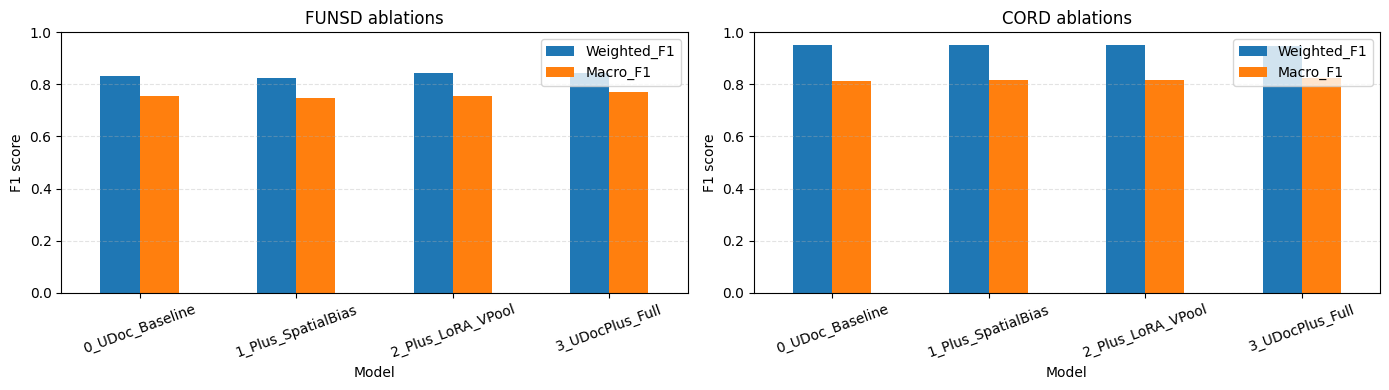

Saved summary: /scratch/m25mac003/omnidoc_outputs/track1_ablation_summary.csv
Saved detailed per-class metrics: /scratch/m25mac003/omnidoc_outputs/track1_detailed_metrics.json
Saved plots under: /scratch/m25mac003/omnidoc_outputs/figures


In [4]:
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from torch.utils.data import Subset

EXPS = [
    ("0_UDoc_Baseline",    dict(use_spatial_bias=False, use_lora_vpool=False, use_query_gate=False)),
    ("1_Plus_SpatialBias", dict(use_spatial_bias=True,  use_lora_vpool=False, use_query_gate=False)),
    ("2_Plus_LoRA_VPool",  dict(use_spatial_bias=True,  use_lora_vpool=True,  use_query_gate=False)),
    ("3_UDocPlus_Full",    dict(use_spatial_bias=True,  use_lora_vpool=True,  use_query_gate=True)),
]

TRACK1_DATASETS = tuple(
    name.strip().lower()
    for name in os.environ.get("UDOC_TRACK1_DATASETS", "funsd,cord").split(",")
    if name.strip()
)
CLASS_NAMES = {"funsd": ["other", "header", "question", "answer"]}


@torch.no_grad()
def evaluate_regions(model, dataset, class_names):
    model.eval()
    predictions, gold = [], []

    for index in range(len(dataset)):
        sample = dataset[index]
        tokens = TEXT_TOK(
            sample["texts"],
            padding=True,
            truncation=True,
            max_length=64,
            return_tensors="pt",
        ).to(DEVICE)

        with amp_context():
            output = model(
                sample["image"].unsqueeze(0).to(DEVICE),
                sample["boxes_px"].to(DEVICE),
                sample["boxes_6d"].to(DEVICE),
                tokens["input_ids"],
                tokens["attention_mask"],
            )

        predictions.extend(output["logits"].argmax(-1).cpu().tolist())
        gold.extend(sample["labels"].tolist())

    labels = list(range(len(class_names)))
    report = classification_report(
        gold,
        predictions,
        labels=labels,
        target_names=class_names,
        output_dict=True,
        zero_division=0,
    )

    return {
        "weighted_f1": float(
            f1_score(gold, predictions, average="weighted", zero_division=0)
        ),
        "macro_f1": float(
            f1_score(gold, predictions, average="macro", zero_division=0)
        ),
        "per_class": {
            name: {
                key: float(report[name][key])
                for key in ("precision", "recall", "f1-score", "support")
            }
            for name in class_names
        },
        "confusion_matrix": confusion_matrix(
            gold, predictions, labels=labels
        ).tolist(),
    }


def subset_dataset(dataset, limit, seed):
    if limit is None or len(dataset) <= limit:
        return dataset

    indices = np.random.default_rng(seed).permutation(len(dataset))[:limit].tolist()
    return Subset(dataset, indices)


if not TRACK1_DATASETS or set(TRACK1_DATASETS) - {"funsd", "cord"}:
    raise ValueError(
        "UDOC_TRACK1_DATASETS must be a comma-separated subset of funsd,cord."
    )
if "funsd" not in TRACK1_DATASETS:
    raise ValueError(
        "Include FUNSD in Track 1; its full-model checkpoint initializes "
        "the Track 2 retriever."
    )

track1_rows = []
TRACK1_COUNTS = {}

for dataset_name in TRACK1_DATASETS:
    if dataset_name == "funsd":
        train_full, test_full = funsd_train, funsd_test
        class_names = CLASS_NAMES["funsd"]
    else:
        train_full = CORDRegionDataset("train")
        test_full = CORDRegionDataset(
            "test",
            label2id=train_full.label2id,
        )
        class_names = train_full.class_names

    CLASS_NAMES[dataset_name] = class_names

    train_ds = subset_dataset(train_full, CFG["track1_max_train"], seed=42)
    test_ds = subset_dataset(test_full, CFG["track1_max_test"], seed=43)

    if len(train_ds) < 2:
        raise ValueError(f"{dataset_name} needs at least two training documents.")

    order = np.random.default_rng(44).permutation(len(train_ds)).tolist()
    val_count = max(1, round(len(order) * 0.1))
    val_ds = Subset(train_ds, order[:val_count])
    fit_ds = Subset(train_ds, order[val_count:])

    TRACK1_COUNTS[dataset_name] = {
        "training_pool": len(train_full),
        "fit": len(fit_ds),
        "validation": len(val_ds),
        "test_pool": len(test_full),
        "test_evaluated": len(test_ds),
    }

    print(
        f"\n{dataset_name.upper()}: "
        f"fit={len(fit_ds)}, validation={len(val_ds)}, "
        f"test={len(test_ds)}, classes={len(class_names)}"
    )

    for experiment_index, (name, flags) in enumerate(EXPS, start=1):
        seed_all(42)

        model = UDocPlus(
            num_classes=len(class_names),
            **flags,
        ).to(DEVICE)

        trainable = [
            parameter for parameter in model.parameters()
            if parameter.requires_grad
        ]
        optimizer = torch.optim.AdamW(
            trainable,
            lr=2e-4,
            weight_decay=1e-4,
        )
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
            optimizer,
            T_max=CFG["track1_epochs"],
            eta_min=1e-6,
        )
        scaler = torch.cuda.amp.GradScaler(
            enabled=(DEVICE.type == "cuda" and AMP_DTYPE == torch.float16)
        )

        best_val_f1 = -1.0
        checkpoint_path = (
            Path(WORK_DIR)
            / "checkpoints"
            / f"best_udoc_plus_{dataset_name}_{name}.pt"
        )

        print(
            f"  Training model {experiment_index}/{len(EXPS)}: {name} "
            f"({CFG['track1_epochs']} epochs)"
        )

        for epoch in range(1, CFG["track1_epochs"] + 1):
            model.train()
            optimizer.zero_grad(set_to_none=True)
            indices = np.random.permutation(len(fit_ds))

            for step, sample_idx in enumerate(indices, start=1):
                sample = fit_ds[int(sample_idx)]
                tokens = TEXT_TOK(
                    sample["texts"],
                    padding=True,
                    truncation=True,
                    max_length=64,
                    return_tensors="pt",
                ).to(DEVICE)

                with amp_context():
                    output = model(
                        sample["image"].unsqueeze(0).to(DEVICE),
                        sample["boxes_px"].to(DEVICE),
                        sample["boxes_6d"].to(DEVICE),
                        tokens["input_ids"],
                        tokens["attention_mask"],
                    )
                    loss = udoc_plus_loss(
                        output,
                        sample["labels"].to(DEVICE),
                    ) / 8.0

                scaler.scale(loss).backward()

                if step % 8 == 0 or step == len(indices):
                    scaler.unscale_(optimizer)
                    torch.nn.utils.clip_grad_norm_(trainable, 1.0)
                    scaler.step(optimizer)
                    scaler.update()
                    optimizer.zero_grad(set_to_none=True)

            scheduler.step()
            validation = evaluate_regions(model, val_ds, class_names)

            if validation["weighted_f1"] > best_val_f1:
                best_val_f1 = validation["weighted_f1"]
                torch.save(
                    {
                        "state_dict": model.state_dict(),
                        "class_names": class_names,
                        "dataset": dataset_name,
                        "flags": flags,
                    },
                    checkpoint_path,
                )

        # Select the best validation checkpoint, then evaluate test data once.
        state = torch.load(checkpoint_path, map_location=DEVICE)
        model.load_state_dict(state["state_dict"])
        test = evaluate_regions(model, test_ds, class_names)

        row = {
            "Dataset": dataset_name,
            "Model": name,
            "Trainable_M": round(
                sum(parameter.numel() for parameter in trainable) / 1e6,
                2,
            ),
            "Best_Validation_Weighted_F1": round(best_val_f1, 4),
            "Weighted_F1": round(test["weighted_f1"], 4),
            "Macro_F1": round(test["macro_f1"], 4),
            "Train_N": len(fit_ds),
            "Validation_N": len(val_ds),
            "Test_N": len(test_ds),
            "Class_Names": class_names,
            "Per_Class": test["per_class"],
            "Confusion_Matrix": test["confusion_matrix"],
        }
        track1_rows.append(row)

        if name == "3_UDocPlus_Full" and dataset_name == "funsd":
            torch.save(
                state["state_dict"],
                Path(WORK_DIR) / "checkpoints" / "best_udoc_plus.pt",
            )

        # Save a row-normalized confusion matrix without displaying it inline.
        matrix = np.asarray(test["confusion_matrix"], dtype=float)
        matrix /= np.maximum(matrix.sum(axis=1, keepdims=True), 1)

        fig, ax = plt.subplots(
            figsize=(
                max(6, len(class_names) * 0.45),
                max(5, len(class_names) * 0.4),
            )
        )
        ax.imshow(matrix, cmap="Blues", vmin=0, vmax=1)
        ax.set(
            xticks=range(len(class_names)),
            yticks=range(len(class_names)),
            xticklabels=class_names,
            yticklabels=class_names,
            xlabel="Predicted label",
            ylabel="True label",
            title=f"{dataset_name.upper()} — {name}",
        )
        ax.tick_params(axis="both", labelsize=7)
        plt.setp(ax.get_xticklabels(), rotation=35, ha="right")

        for y in range(matrix.shape[0]):
            for x in range(matrix.shape[1]):
                ax.text(
                    x,
                    y,
                    f"{matrix[y, x]:.2f}",
                    ha="center",
                    va="center",
                    fontsize=7,
                )

        fig.tight_layout()
        fig.savefig(
            Path(WORK_DIR) / "figures" / f"confusion_{dataset_name}_{name}.png",
            dpi=200,
        )
        plt.close(fig)

        print(
            f"    Test weighted F1={test['weighted_f1']:.4f} | "
            f"macro F1={test['macro_f1']:.4f} | "
            f"best validation weighted F1={best_val_f1:.4f}"
        )

        del model, optimizer, scheduler, trainable, loss
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

# Compact results table for display.
summary_columns = [
    "Dataset",
    "Model",
    "Trainable_M",
    "Best_Validation_Weighted_F1",
    "Weighted_F1",
    "Macro_F1",
    "Train_N",
    "Validation_N",
    "Test_N",
]
df_t1 = pd.DataFrame(track1_rows)[summary_columns]

summary_path = Path(WORK_DIR) / "track1_ablation_summary.csv"
details_path = Path(WORK_DIR) / "track1_detailed_metrics.json"

df_t1.to_csv(summary_path, index=False)
details_path.write_text(
    json.dumps(track1_rows, indent=2),
    encoding="utf-8",
)

print("\nTrack 1 test results:")
display(df_t1)

# One comparison chart for the notebook output.
fig, axes = plt.subplots(
    1,
    len(TRACK1_DATASETS),
    figsize=(7 * len(TRACK1_DATASETS), 4),
    squeeze=False,
)

for ax, dataset_name in zip(axes[0], TRACK1_DATASETS):
    subset = df_t1[df_t1["Dataset"] == dataset_name]
    subset.plot(
        x="Model",
        y=["Weighted_F1", "Macro_F1"],
        kind="bar",
        ax=ax,
        rot=20,
    )
    ax.set_title(f"{dataset_name.upper()} ablations")
    ax.set_ylabel("F1 score")
    ax.set_ylim(0, 1)
    ax.grid(axis="y", linestyle="--", alpha=0.35)

fig.tight_layout()
comparison_path = Path(WORK_DIR) / "figures" / "track1_ablation_comparison.png"
fig.savefig(comparison_path, dpi=220, bbox_inches="tight")
plt.show()

print(f"Saved summary: {summary_path}")
print(f"Saved detailed per-class metrics: {details_path}")
print(f"Saved plots under: {Path(WORK_DIR) / 'figures'}")

## 4. Track 2 data: MMLongBench-Doc and MP-DocVQA

Download bounded samples from both sources. Split by document ID so questions from one PDF cannot cross between training and evaluation. MMLongBench evidence pages are one-based; MP-DocVQA answer page indexes are zero-based. MP-DocVQA page images are assembled into local PDFs so both sources use the same parser and retriever.


In [5]:
from collections import defaultdict
from huggingface_hub import HfApi, hf_hub_download
from datasets import load_dataset
from PIL import Image


def parse_list_str(value):
    if value is None:
        return []
    if isinstance(value, (list, tuple)):
        return list(value)
    try:
        parsed = ast.literal_eval(str(value).strip())
        return list(parsed) if isinstance(parsed, (list, tuple)) else [parsed]
    except (ValueError, SyntaxError):
        return [str(value)]


VISION_KEYS = ("table", "chart", "figure", "layout", "image", "diagram")
train_qas, eval_qas, local_pdfs = [], [], {}

# MMLongBench-Doc stores the PDF name in doc_id and the files under documents/.
print("Loading MMLongBench-Doc metadata...")
mm_ds = load_dataset("yubo2333/MMLongBench-Doc", split="train")
repo_files = HfApi().list_repo_files("yubo2333/MMLongBench-Doc", repo_type="dataset")
pdf_map = {os.path.basename(filename): filename for filename in repo_files if filename.lower().endswith(".pdf")}
mm_by_doc = defaultdict(list)
for row in mm_ds:
    doc_name = str(row.get("doc_id", "")).strip()
    question, answer = str(row.get("question", "")).strip(), str(row.get("answer", "")).strip()
    if doc_name and doc_name in pdf_map and question and answer and answer.lower() not in ("not answerable", "unanswerable"):
        mm_by_doc[doc_name].append(row)
mm_docs = sorted(mm_by_doc)
random.Random(42).shuffle(mm_docs)
mm_docs = mm_docs[:CFG["mmlong_max_docs"]]
mm_pdf_dir = Path(WORK_DIR) / "pdfs" / "mmlongbench"
mm_pdf_dir.mkdir(parents=True, exist_ok=True)
mm_downloaded = []
for doc_name in mm_docs:
    try:
        path = hf_hub_download(repo_id="yubo2333/MMLongBench-Doc", filename=pdf_map[doc_name],
                               repo_type="dataset", local_dir=str(mm_pdf_dir))
    except Exception as exc:
        print(f"Skipping MMLongBench PDF {doc_name}: {exc}")
        continue
    doc_id = f"mmlong::{doc_name}"
    local_pdfs[doc_id] = path
    mm_downloaded.append(doc_name)
if len(mm_downloaded) < 2:
    raise RuntimeError(f"Need at least two downloadable MMLongBench documents for a document-disjoint split; got {len(mm_downloaded)}.")
mm_train_n = min(len(mm_downloaded) - 1, max(1, int(len(mm_downloaded) * CFG["train_ratio"])))
mm_train_docs = set(mm_downloaded[:mm_train_n])
for doc_name in mm_downloaded:
    for row in mm_by_doc[doc_name]:
        gold_pages = []
        for page in parse_list_str(row.get("evidence_pages")):
            try:
                page = int(page)
                if page >= 1:
                    gold_pages.append(page - 1)
            except (TypeError, ValueError):
                continue
        sources = [str(value).lower() for value in parse_list_str(row.get("evidence_sources"))]
        record = {"doc_id": f"mmlong::{doc_name}", "pdf_path": local_pdfs[f"mmlong::{doc_name}"],
                  "query": str(row["question"]).strip(), "answers": [str(row["answer"]).strip()],
                  "gold_pages": gold_pages, "needs_vision": int(any(k in source for source in sources for k in VISION_KEYS)),
                  "is_cross_page": int(len(set(gold_pages)) > 1), "source": "MMLongBench-Doc"}
        (train_qas if doc_name in mm_train_docs else eval_qas).append(record)

# MP-DocVQA exposes page images rather than a PDF; assemble and persist each document once.
print("Streaming MP-DocVQA sample...")
mp_stream = load_dataset("lmms-lab/MP-DocVQA", split="val", streaming=True)
mp_by_doc, mp_pdf_paths = defaultdict(list), {}
mp_dir = Path(WORK_DIR) / "pdfs" / "mp_docvqa"
mp_dir.mkdir(parents=True, exist_ok=True)
accepted = 0
for row_index, row in enumerate(mp_stream):
    if accepted >= CFG["mp_docvqa_max_samples"]:
        break
    query = str(row.get("question", "")).strip()
    answers = [str(answer).strip() for answer in parse_list_str(row.get("answers")) if str(answer).strip()]
    if not query or not answers:
        continue
    original_id = str(row.get("doc_id", row.get("document_id", f"row_{row_index}"))).strip()
    doc_id = f"mpdocvqa::{original_id}"
    if doc_id not in mp_pdf_paths:
        page_images = [row.get(f"image_{index}") for index in range(1, 21)]
        page_images = [image.convert("RGB") for image in page_images if image is not None and hasattr(image, "convert")]
        if not page_images:
            continue
        safe_name = re.sub(r"[^A-Za-z0-9_.-]", "_", original_id)[:100] or f"row_{row_index}"
        pdf_path = mp_dir / f"{safe_name}.pdf"
        page_images[0].save(pdf_path, "PDF", resolution=120, save_all=True, append_images=page_images[1:])
        mp_pdf_paths[doc_id] = str(pdf_path)
        local_pdfs[doc_id] = str(pdf_path)
    try:
        page = int(row.get("answer_page_idx", 0))
        page = max(0, page)
    except (TypeError, ValueError):
        page = 0
    mp_by_doc[doc_id].append({"doc_id": doc_id, "pdf_path": mp_pdf_paths[doc_id], "query": query,
                              "answers": answers, "gold_pages": [page], "needs_vision": None,
                              "is_cross_page": 0, "source": "MP-DocVQA"})
    accepted += 1
mp_docs = sorted(mp_by_doc)
random.Random(43).shuffle(mp_docs)
if len(mp_docs) < 2:
    raise RuntimeError(f"Need at least two MP-DocVQA documents for a document-disjoint split; got {len(mp_docs)}.")
mp_train_n = min(len(mp_docs) - 1, max(1, int(len(mp_docs) * CFG["train_ratio"])))
mp_train_docs = set(mp_docs[:mp_train_n])
for doc_id in mp_docs:
    (train_qas if doc_id in mp_train_docs else eval_qas).extend(mp_by_doc[doc_id])

# Bound evaluation independently by source while preserving every selected eval document.
for source in ("MMLongBench-Doc", "MP-DocVQA"):
    source_eval = [qa for qa in eval_qas if qa["source"] == source]
    if len(source_eval) > CFG["max_eval_qas"]:
        selected = set(id(qa) for qa in source_eval[:CFG["max_eval_qas"]])
        eval_qas = [qa for qa in eval_qas if qa["source"] != source or id(qa) in selected]

if not train_qas or not eval_qas:
    raise RuntimeError(f"Both training and evaluation records are required (train={len(train_qas)}, eval={len(eval_qas)}).")
print(f"MMLongBench: {mm_train_n} train docs / {len(mm_downloaded)-mm_train_n} eval docs; "
      f"MP-DocVQA: {mp_train_n} train docs / {len(mp_docs)-mp_train_n} eval docs.")
print(f"Combined QA records: train={len(train_qas)}, evaluation={len(eval_qas)}, PDFs={len(local_pdfs)}")


Loading MMLongBench-Doc metadata...


documents/0b85477387a9d0cc33fca0f4becaa0(…):   0%|          | 0.00/6.79M [00:00<?, ?B/s]

documents/tacl_a_00660.pdf:   0%|          | 0.00/1.11M [00:00<?, ?B/s]

documents/efd88e41c5f2606c57929cac6c1c06(…):   0%|          | 0.00/1.29M [00:00<?, ?B/s]

e79deb02a0c0e87511080836c5d4347b.pdf: 0.00B [00:00, ?B/s]

documents/PP_2021.04.22_voting-access_RE(…):   0%|          | 0.00/3.18M [00:00<?, ?B/s]

... (47 outputs left out)

Resolving data files:   0%|          | 0/23 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/29 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/23 [00:00<?, ?it/s]

MMLongBench: 36 train docs / 24 eval docs; MP-DocVQA: 33 train docs / 23 eval docs.
Combined QA records: train=417, evaluation=230, PDFs=116


## 5. PDF parsing and Focus-Canvas

Extract text, tables, and figures from each selected PDF. Scanned pages use EasyOCR when available text is too sparse. The graph connects reading order, headings, captions, cross-page continuations, and explicit references.

Consider using the pymupdf_layout package for a greatly improved page layout analysis.
MuPDF error: syntax error: could not parse color space (301 0 R)

MuPDF error: syntax error: could not parse color space (301 0 R)

MuPDF error: syntax error: could not parse color space (301 0 R)

MuPDF error: syntax error: could not parse color space (301 0 R)

MuPDF error: syntax error: could not parse color space (301 0 R)

MuPDF error: syntax error: could not parse color space (301 0 R)

MuPDF error: syntax error: could not parse color space (301 0 R)

MuPDF error: syntax error: could not parse color space (301 0 R)

MuPDF error: syntax error: could not parse color space (301 0 R)

MuPDF error: syntax error: could not parse color space (301 0 R)

MuPDF error: syntax error: could not parse color space (301 0 R)

MuPDF error: syntax error: could not parse color space (301 0 R)

MuPDF error: syntax error: could not parse color space (301 0 R)

MuPDF error: syntax error: could not parse color space 

,Documents parsed,Total pages,Total regions,Cross-page bridge edges
0,116,2397,48662,39661


Saved per-document details to: /scratch/m25mac003/omnidoc_outputs/parsed_document_summary.csv


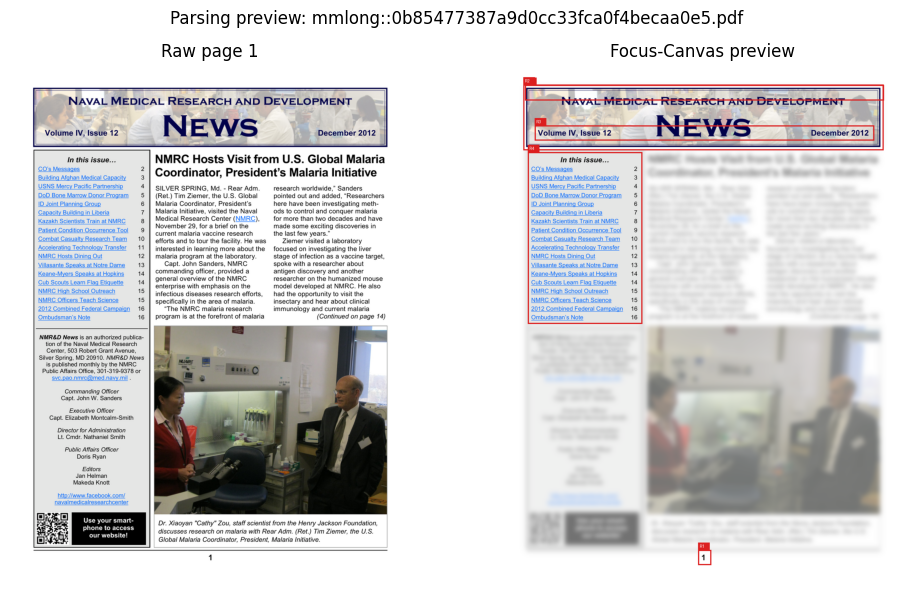

Saved Focus-Canvas preview to: /scratch/m25mac003/omnidoc_outputs/figures/fig2_focus_canvas_preview.png


In [6]:
import fitz
import cv2
import networkx as nx
from PIL import Image, ImageDraw

XREF_RE = re.compile(
    r"\b(Table|Fig\.?|Figure|Section|Appendix)\s+"
    r"(\d+(?:\.\d+)?|[A-Z])\b",
    re.IGNORECASE,
)
_OCR = None


def _ocr_page(pil_img, page_index, start_id):
    global _OCR

    if _OCR is None:
        import easyocr

        _OCR = easyocr.Reader(
            ["en"],
            gpu=(DEVICE.type == "cuda"),
            model_storage_directory=str(Path(WORK_DIR) / "cache" / "easyocr"),
        )

    width, height = pil_img.size
    regions, region_id = [], start_id

    for quad, text in _OCR.readtext(np.array(pil_img), paragraph=True):
        text = text.strip()
        if not text:
            continue

        xs = [point[0] for point in quad]
        ys = [point[1] for point in quad]

        x1 = max(0.0, min(xs) / width)
        y1 = max(0.0, min(ys) / height)
        x2 = min(1.0, max(x1 + 1e-3, max(xs) / width))
        y2 = min(1.0, max(y1 + 1e-3, max(ys) / height))

        digit_ratio = sum(char.isdigit() for char in text) / max(len(text), 1)
        region_type = "table" if digit_ratio > 0.25 else "text"

        regions.append(
            {
                "id": region_id,
                "page": page_index,
                "type": region_type,
                "text": text,
                "box_6d": [
                    x1, y1, x2, y2,
                    x2 - x1, y2 - y1,
                ],
            }
        )
        region_id += 1

    if not regions:
        regions.append(
            {
                "id": region_id,
                "page": page_index,
                "type": "figure",
                "text": f"[Visual Page {page_index + 1}]",
                "box_6d": [0.05, 0.05, 0.95, 0.95, 0.9, 0.9],
            }
        )

    return regions, region_id


def _horiz_iou(box_a, box_b):
    intersection = max(
        0.0,
        min(box_a[2], box_b[2]) - max(box_a[0], box_b[0]),
    )
    union = max(box_a[2], box_b[2]) - min(box_a[0], box_b[0])
    return intersection / (union + 1e-6)


def parse_pdf(pdf_path, dpi=120, max_pages=60):
    """Render a PDF and extract text, image, table, and OCR regions."""
    pages = []
    regions = []
    region_id = 0

    with fitz.open(pdf_path) as document:
        for page_index in range(min(len(document), max_pages)):
            page = document[page_index]
            pixmap = page.get_pixmap(dpi=dpi)
            image = Image.frombytes(
                "RGB",
                [pixmap.width, pixmap.height],
                pixmap.samples,
            )

            if max(image.size) > 1280:
                scale = 1280 / max(image.size)
                image = image.resize(
                    (
                        int(image.width * scale),
                        int(image.height * scale),
                    ),
                    Image.Resampling.LANCZOS,
                )

            pages.append(image)
            page_width = max(page.rect.width, 1.0)
            page_height = max(page.rect.height, 1.0)

            if len(page.get_text("text").strip()) < 20:
                page_regions, region_id = _ocr_page(
                    image,
                    page_index,
                    region_id,
                )
                regions.extend(page_regions)
                continue

            page_regions = []

            for block in page.get_text("dict").get("blocks", []):
                if block["type"] == 0:
                    lines = []
                    font_sizes = []

                    for line in block.get("lines", []):
                        spans = [
                            span["text"].strip()
                            for span in line.get("spans", [])
                            if span["text"].strip()
                        ]
                        font_sizes.extend(
                            span["size"] for span in line.get("spans", [])
                        )
                        if spans:
                            lines.append(" ".join(spans))

                    text = " ".join(lines).strip()
                    if not text:
                        continue

                    x1, y1, x2, y2 = block["bbox"]

                    if re.match(r"^(Table|Fig\.?|Figure)\s+\d+", text, re.I):
                        region_type = "caption"
                    elif (np.mean(font_sizes) if font_sizes else 10) >= 13.0 and len(text.split()) <= 16:
                        region_type = "header"
                    else:
                        region_type = "text"

                elif block["type"] == 1:
                    x1, y1, x2, y2 = block["bbox"]
                    text = f"[Visual Figure on Page {page_index + 1}]"
                    region_type = "figure"
                else:
                    continue

                x1n = max(0.0, min(1.0, x1 / page_width))
                y1n = max(0.0, min(1.0, y1 / page_height))
                x2n = min(1.0, max(x1n + 1e-3, x2 / page_width))
                y2n = min(1.0, max(y1n + 1e-3, y2 / page_height))

                page_regions.append(
                    {
                        "id": region_id,
                        "page": page_index,
                        "type": region_type,
                        "text": text,
                        "box_6d": [
                            x1n, y1n, x2n, y2n,
                            x2n - x1n, y2n - y1n,
                        ],
                    }
                )
                region_id += 1

            try:
                for table in page.find_tables().tables:
                    tx1, ty1, tx2, ty2 = [
                        table.bbox[0] / page_width,
                        table.bbox[1] / page_height,
                        table.bbox[2] / page_width,
                        table.bbox[3] / page_height,
                    ]

                    for region in page_regions:
                        box = region["box_6d"]
                        intersection = (
                            max(0, min(box[2], tx2) - max(box[0], tx1))
                            * max(0, min(box[3], ty2) - max(box[1], ty1))
                        )
                        if intersection / max(1e-6, box[4] * box[5]) > 0.5:
                            region["type"] = "table"

            except (AttributeError, RuntimeError, ValueError):
                pass

            regions.extend(page_regions)

    if not pages:
        raise ValueError(f"No readable PDF pages found in {pdf_path}")
    if not regions:
        raise ValueError(f"No text, image, or OCR regions extracted from {pdf_path}")

    return pages, regions


def build_cross_page_graph(regions):
    """Build reading-order, reference, caption, and continuation links."""
    region_count = len(regions)
    graph = nx.DiGraph()
    adjacency = torch.zeros((region_count, region_count), dtype=torch.float32)
    regions_by_page = {}

    for region in regions:
        graph.add_node(region["id"], **region)
        regions_by_page.setdefault(region["page"], []).append(region)

    active_header = None
    anchors = {}

    for page_index in sorted(regions_by_page):
        page_regions = sorted(
            regions_by_page[page_index],
            key=lambda region: (
                round(region["box_6d"][1], 2),
                region["box_6d"][0],
            ),
        )

        for index, region in enumerate(page_regions):
            region_id = region["id"]

            if index + 1 < len(page_regions):
                graph.add_edge(
                    region_id,
                    page_regions[index + 1]["id"],
                    rel="NEXT_IN_FLOW",
                )

            if region["type"] == "header":
                active_header = region_id
            elif active_header is not None:
                graph.add_edge(active_header, region_id, rel="PARENT_OF")
                if regions[active_header]["page"] != page_index:
                    adjacency[active_header, region_id] = 3.0
                    adjacency[region_id, active_header] = 3.0

            if region["type"] == "caption":
                match = XREF_RE.search(region["text"])
                if match:
                    key = (
                        f"{match.group(1).lower().rstrip('.')} "
                        f"{match.group(2).lower()}"
                    )
                    anchors[key] = region_id

                visual_regions = [
                    item for item in page_regions
                    if item["type"] in ("figure", "table")
                ]
                if visual_regions:
                    nearest = min(
                        visual_regions,
                        key=lambda item: abs(
                            item["box_6d"][1] - region["box_6d"][1]
                        ),
                    )
                    graph.add_edge(region_id, nearest["id"], rel="CAPTION_OF")
                    graph.add_edge(nearest["id"], region_id, rel="CAPTION_OF")

        # Link likely table or column continuations across adjacent pages.
        if page_index + 1 in regions_by_page:
            bottom_regions = [
                region for region in page_regions
                if region["box_6d"][3] > 0.72
            ]
            top_regions = [
                region for region in regions_by_page[page_index + 1]
                if region["box_6d"][1] < 0.28
            ]

            for bottom_region in bottom_regions:
                for top_region in top_regions:
                    if _horiz_iou(
                        bottom_region["box_6d"],
                        top_region["box_6d"],
                    ) > 0.60:
                        graph.add_edge(
                            bottom_region["id"],
                            top_region["id"],
                            rel="CONTINUES_ON",
                        )
                        graph.add_edge(
                            top_region["id"],
                            bottom_region["id"],
                            rel="CONTINUES_ON",
                        )
                        adjacency[bottom_region["id"], top_region["id"]] = 1.0
                        adjacency[top_region["id"], bottom_region["id"]] = 1.0

    # Link text that explicitly references a captioned table or figure.
    for region in regions:
        if region["type"] == "caption":
            continue

        for match in XREF_RE.finditer(region["text"]):
            key = (
                f"{match.group(1).lower().rstrip('.')} "
                f"{match.group(2).lower()}"
            )
            target_id = anchors.get(key)

            if target_id is not None and target_id != region["id"]:
                graph.add_edge(region["id"], target_id, rel="REFERS_TO")
                adjacency[region["id"], target_id] = 2.0
                adjacency[target_id, region["id"]] = 2.0

    return graph, adjacency


def render_focus_canvas(
    pil_page,
    target_regions,
    blur_sigma=6,
    dim_alpha=0.45,
    max_side=1280,
):
    """Keep selected regions sharp and dim the rest of the page."""
    image = pil_page.convert("RGB")
    width, height = image.size

    if max(width, height) > max_side:
        scale = max_side / float(max(width, height))
        image = image.resize(
            (int(width * scale), int(height * scale)),
            Image.Resampling.LANCZOS,
        )
        width, height = image.size

    array = np.array(image)
    background = cv2.GaussianBlur(
        array,
        (0, 0),
        sigmaX=blur_sigma,
    ).astype(np.float32)
    background = (
        background * (1 - dim_alpha) + 255 * dim_alpha
    ).astype(np.uint8)
    canvas = background.copy()

    boxes = []
    for region in target_regions:
        x1, y1, x2, y2, _, _ = region["box_6d"]
        px1 = max(0, int(x1 * width) - 8)
        py1 = max(0, int(y1 * height) - 8)
        px2 = min(width, max(px1 + 6, int(x2 * width) + 8))
        py2 = min(height, max(py1 + 6, int(y2 * height) + 8))

        canvas[py1:py2, px1:px2] = array[py1:py2, px1:px2]
        boxes.append((region["id"], px1, py1, px2, py2))

    output = Image.fromarray(canvas)
    draw = ImageDraw.Draw(output)

    for region_id, px1, py1, px2, py2 in boxes:
        label = f"R{region_id}"
        label_y = max(0, py1 - 18)
        draw.rectangle([px1, py1, px2, py2], outline=(220, 30, 30), width=3)
        draw.rectangle(
            [px1, label_y, min(width, px1 + 10 * len(label) + 8), min(height, label_y + 18)],
            fill=(220, 30, 30),
        )
        draw.text((px1 + 4, label_y + 3), label, fill=(255, 255, 255))

    return output


# Parse PDFs and build their cross-page graphs.
if not local_pdfs:
    raise RuntimeError("No PDFs are available in local_pdfs to parse.")

PARSED_DOCS = {}
document_rows = []

for doc_id, pdf_path in local_pdfs.items():
    pages, regions = parse_pdf(pdf_path)
    graph, adjacency = build_cross_page_graph(regions)

    PARSED_DOCS[doc_id] = {
        "pages": pages,
        "regions": regions,
        "graph": graph,
        "bridge_adj": adjacency,
    }

    bridge_edges = int(torch.triu(adjacency > 0, diagonal=1).sum().item())
    document_rows.append(
        {
            "Document": doc_id,
            "Pages": len(pages),
            "Regions": len(regions),
            "Cross-page bridge edges": bridge_edges,
        }
    )

# Release EasyOCR before loading the larger VLM.
if _OCR is not None:
    del _OCR
    _OCR = None
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# Show a compact corpus summary and save document-level details.
document_summary = pd.DataFrame(document_rows)
document_summary_path = Path(WORK_DIR) / "parsed_document_summary.csv"
document_summary.to_csv(document_summary_path, index=False)

corpus_summary = pd.DataFrame(
    [
        {
            "Documents parsed": len(document_summary),
            "Total pages": int(document_summary["Pages"].sum()),
            "Total regions": int(document_summary["Regions"].sum()),
            "Cross-page bridge edges": int(
                document_summary["Cross-page bridge edges"].sum()
            ),
        }
    ]
)

display(corpus_summary)
print(f"Saved per-document details to: {document_summary_path}")

# Show one representative raw-page / Focus-Canvas comparison.
sample_doc_id = sorted(PARSED_DOCS)[0]
sample_doc = PARSED_DOCS[sample_doc_id]
sample_page_id = next(
    (
        page_id
        for page_id in range(len(sample_doc["pages"]))
        if any(region["page"] == page_id for region in sample_doc["regions"])
    ),
    0,
)
sample_regions = [
    region
    for region in sample_doc["regions"]
    if region["page"] == sample_page_id
][:5]

fig, axes = plt.subplots(1, 2, figsize=(10, 6))
axes[0].imshow(sample_doc["pages"][sample_page_id])
axes[0].set_title(f"Raw page {sample_page_id + 1}")
axes[0].axis("off")

axes[1].imshow(
    render_focus_canvas(
        sample_doc["pages"][sample_page_id],
        sample_regions,
    )
)
axes[1].set_title("Focus-Canvas preview")
axes[1].axis("off")

fig.suptitle(f"Parsing preview: {sample_doc_id}")
fig.tight_layout()

preview_path = Path(WORK_DIR) / "figures" / "fig2_focus_canvas_preview.png"
fig.savefig(preview_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"Saved Focus-Canvas preview to: {preview_path}")

## 6. Retriever and visual-gate training

Warm-start from the FUNSD full-model checkpoint, then train on positive regions from the document-disjoint training portions of both QA datasets. MP-DocVQA visual labels are inferred from the answer-bearing region type; MMLongBench labels use the published evidence-source annotations.


In [7]:
def locate_pos_region(regions, gold_pages, query, answers):
    if not regions:
        raise ValueError("Cannot find a positive region in a document with no extracted regions.")

    candidates = [region for region in regions if region["page"] in set(gold_pages)] or regions
    answer_terms = [
        str(answer).lower().strip()
        for answer in answers
        if len(str(answer).strip()) >= 2
    ]

    for region in candidates:
        if any(answer in region["text"].lower() for answer in answer_terms):
            return region["id"]

    query_terms = set(
        re.findall(r"\w+", (query + " " + " ".join(answer_terms)).lower())
    )
    return max(
        candidates,
        key=lambda region: len(
            query_terms & set(re.findall(r"\w+", region["text"].lower()))
        ),
    )["id"]


# Derive MP-DocVQA modality labels from the answer-bearing region.
for qa in train_qas + eval_qas:
    if qa["needs_vision"] is None:
        regions = PARSED_DOCS[qa["doc_id"]]["regions"]
        positive_id = locate_pos_region(
            regions, qa["gold_pages"], qa["query"], qa["answers"]
        )
        qa["needs_vision"] = int(
            regions[positive_id]["type"] in ("table", "figure")
        )

# Save the train/evaluation manifests used for this run.
for split_name, records in (("train", train_qas), ("eval", eval_qas)):
    manifest_path = Path(WORK_DIR) / f"track2_{split_name}_manifest.jsonl"
    with manifest_path.open("w", encoding="utf-8") as stream:
        for qa in records:
            stream.write(json.dumps(qa, ensure_ascii=False) + "\n")


# Reuse the trained FUNSD full-model encoder.
udoc_rag = UDocPlus(
    num_classes=4,
    use_spatial_bias=True,
    use_lora_vpool=True,
    use_query_gate=True,
).to(DEVICE)

track1_checkpoint = Path(WORK_DIR) / "checkpoints" / "best_udoc_plus.pt"
if not track1_checkpoint.exists():
    raise FileNotFoundError(
        f"FUNSD full-model checkpoint not found: {track1_checkpoint}. "
        "Run Track 1 first."
    )

state = torch.load(track1_checkpoint, map_location=DEVICE)
if isinstance(state, dict) and "state_dict" in state:
    state = state["state_dict"]
udoc_rag.load_state_dict(state, strict=False)


def pack_doc_tensors(doc_dict, max_regs=None, focus_region_id=None):
    """Pack one PDF, centering the capped region window on the positive region."""
    if not doc_dict["pages"] or not doc_dict["regions"]:
        raise ValueError(
            "Cannot pack a document without rendered pages and extracted regions."
        )

    all_regions = doc_dict["regions"]
    positions = list(range(len(all_regions)))

    if max_regs and len(positions) > max_regs:
        anchor = next(
            (
                index
                for index, region in enumerate(all_regions)
                if region["id"] == focus_region_id
            ),
            0,
        )
        start = max(0, min(anchor - max_regs // 2, len(positions) - max_regs))
        positions = positions[start : start + max_regs]

    regs = [all_regions[index] for index in positions]
    position_tensor = torch.tensor(
        positions,
        dtype=torch.long,
        device=doc_dict["bridge_adj"].device,
    )
    adjacency = (
        doc_dict["bridge_adj"]
        .index_select(0, position_tensor)
        .index_select(1, position_tensor)
    )
    region_ids = [region["id"] for region in regs]

    imgs = torch.stack([IMG_TF(image) for image in doc_dict["pages"]]).to(DEVICE)
    boxes_6d = torch.tensor(
        [region["box_6d"] for region in regs],
        dtype=torch.float32,
        device=DEVICE,
    )
    boxes_px = torch.tensor(
        [
            [
                float(region["page"]),
                region["box_6d"][0] * 512,
                region["box_6d"][1] * 512,
                min(
                    512.0,
                    max(
                        region["box_6d"][0] * 512 + 1,
                        region["box_6d"][2] * 512,
                    ),
                ),
                min(
                    512.0,
                    max(
                        region["box_6d"][1] * 512 + 1,
                        region["box_6d"][3] * 512,
                    ),
                ),
            ]
            for region in regs
        ],
        dtype=torch.float32,
        device=DEVICE,
    )
    page_ids = torch.tensor(
        [region["page"] for region in regs],
        dtype=torch.long,
        device=DEVICE,
    )

    tokens = TEXT_TOK(
        [region["text"] for region in regs],
        padding=True,
        truncation=True,
        max_length=64,
        return_tensors="pt",
    ).to(DEVICE)

    return (
        imgs,
        boxes_px,
        boxes_6d,
        tokens["input_ids"],
        tokens["attention_mask"],
        page_ids,
        adjacency,
        region_ids,
    )


optimizer = torch.optim.AdamW(
    [
        parameter
        for parameter in udoc_rag.parameters()
        if parameter.requires_grad
    ],
    lr=1e-4,
    weight_decay=1e-4,
)
scaler = torch.cuda.amp.GradScaler(
    enabled=(DEVICE.type == "cuda" and AMP_DTYPE == torch.float16)
)

for epoch in range(1, CFG["retriever_epochs"] + 1):
    udoc_rag.train()
    total_loss, steps = 0.0, 0
    random.shuffle(train_qas)

    for qa in train_qas:
        doc = PARSED_DOCS[qa["doc_id"]]
        positive_id = locate_pos_region(
            doc["regions"], qa["gold_pages"], qa["query"], qa["answers"]
        )

        (
            imgs,
            boxes_px,
            boxes_6d,
            ids,
            mask,
            page_ids,
            adjacency,
            region_ids,
        ) = pack_doc_tensors(
            doc,
            max_regs=32,
            focus_region_id=positive_id,
        )
        local_positive_id = region_ids.index(positive_id)

        query_tokens = TEXT_TOK(
            [qa["query"]],
            truncation=True,
            max_length=64,
            return_tensors="pt",
        ).to(DEVICE)

        optimizer.zero_grad(set_to_none=True)

        with amp_context():
            query_emb = udoc_rag.encode_query(
                query_tokens["input_ids"],
                query_tokens["attention_mask"],
            )
            output = udoc_rag(
                imgs,
                boxes_px,
                boxes_6d,
                ids,
                mask,
                page_ids=page_ids,
                bridge_adj=adjacency,
                query_emb=query_emb,
            )
            scores = (output["rag_embs"] @ query_emb.T).squeeze(-1) / 0.07
            retrieval_loss = F.cross_entropy(
                scores.unsqueeze(0),
                torch.tensor([local_positive_id], device=DEVICE),
            )

        # alpha_v is already a probability; compute BCE outside autocast.
        gate_target = torch.tensor(
            float(qa["needs_vision"]),
            dtype=torch.float32,
            device=DEVICE,
        )
        gate_probability = output["alpha_v"][local_positive_id].float().clamp(
            1e-4, 1.0 - 1e-4
        )
        gate_loss = F.binary_cross_entropy(gate_probability, gate_target)
        loss = retrieval_loss.float() + 0.5 * gate_loss

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(
            [
                parameter
                for parameter in udoc_rag.parameters()
                if parameter.requires_grad
            ],
            1.0,
        )
        scaler.step(optimizer)
        scaler.update()

        total_loss += float(loss.detach())
        steps += 1

        del (
            imgs,
            boxes_px,
            boxes_6d,
            ids,
            mask,
            page_ids,
            adjacency,
            query_tokens,
            region_ids,
            output,
        )

    if not steps:
        raise RuntimeError("No retriever training QA could be processed.")

    print(
        f"Retriever/gate epoch {epoch}/{CFG['retriever_epochs']} "
        f"loss={total_loss / steps:.4f} ({steps} QAs)"
    )

rag_checkpoint = Path(WORK_DIR) / "checkpoints" / "udoc_plus_rag.pt"
torch.save(udoc_rag.state_dict(), rag_checkpoint)
del optimizer

_gc = gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

print(f"Saved retriever checkpoint: {rag_checkpoint}")

Retriever/gate epoch 1/10 loss=3.5109 (417 QAs)
Retriever/gate epoch 2/10 loss=2.9943 (417 QAs)
Retriever/gate epoch 3/10 loss=2.0089 (417 QAs)
Retriever/gate epoch 4/10 loss=1.3865 (417 QAs)
Retriever/gate epoch 5/10 loss=0.9002 (417 QAs)
Retriever/gate epoch 6/10 loss=0.6562 (417 QAs)
Retriever/gate epoch 7/10 loss=0.4570 (417 QAs)
Retriever/gate epoch 8/10 loss=0.3624 (417 QAs)
Retriever/gate epoch 9/10 loss=0.3633 (417 QAs)
Retriever/gate epoch 10/10 loss=0.2305 (417 QAs)
Saved retriever checkpoint: /scratch/m25mac003/omnidoc_outputs/checkpoints/udoc_plus_rag.pt


## 7. Index evaluation documents and load inference models

Create dense FAISS and sparse BM25 indexes for evaluation PDFs. Then load the A30-sized Qwen3-VL checkpoint and DeBERTa NLI verifier. Image resolution is capped to prevent Qwen3-VL from expanding page images into excessive visual tokens.


In [8]:
import faiss
from rank_bm25 import BM25Okapi
from transformers import AutoTokenizer, AutoProcessor, AutoModelForImageTextToText, AutoModelForSequenceClassification

if DEVICE.type != "cuda":
    raise RuntimeError("Track 2 VLM evaluation requires a CUDA allocation. Start the notebook inside the Slurm GPU job.")
if "udoc_plus_rag.pt" not in {path.name for path in (Path(WORK_DIR) / "checkpoints").glob("*.pt")}:
    raise FileNotFoundError("RAG checkpoint is missing. Run retriever training first.")
udoc_rag.load_state_dict(torch.load(Path(WORK_DIR) / "checkpoints" / "udoc_plus_rag.pt", map_location=DEVICE))
udoc_rag.eval()
TEST_INDEX = {}
test_doc_ids = sorted({qa["doc_id"] for qa in eval_qas})

with torch.no_grad():
    for did in test_doc_ids:
        doc = PARSED_DOCS[did]
        imgs, bpx, b6d, ids, mask, pids, adj, region_ids = pack_doc_tensors(doc)
        out = udoc_rag.encode_long_doc(imgs, bpx, b6d, ids, mask, pids, adj)
        embs = out["rag_embs"].cpu().numpy().astype("float32")
        f_idx = faiss.IndexFlatIP(embs.shape[1]); f_idx.add(embs)
        bm25 = BM25Okapi([r["text"].lower().split() or ["empty"] for r in doc["regions"]])
        TEST_INDEX[did] = {
            **doc, "faiss": f_idx, "bm25": bm25,
            "tensors": (imgs.cpu(), bpx.cpu(), b6d.cpu(), ids.cpu(), mask.cpu(), pids.cpu(), adj.cpu()),
        }
        del imgs, bpx, b6d, ids, mask, pids, out, embs, region_ids
        torch.cuda.empty_cache()

# Load Open VLM (Qwen3-VL)
print(f"Loading VLM: {VLM_ID} (4-bit={USE_4BIT_VLM})...")
VLM_PROC = AutoProcessor.from_pretrained(
    VLM_ID,
    min_pixels=224 * 224,
    max_pixels=1280 * 1280,
    use_fast=False,
)
if USE_4BIT_VLM:
    from transformers import BitsAndBytesConfig
    bnb_cfg = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_compute_dtype=AMP_DTYPE, bnb_4bit_use_double_quant=True)
    VLM = AutoModelForImageTextToText.from_pretrained(VLM_ID, quantization_config=bnb_cfg, device_map="auto").eval()
else:
    VLM = AutoModelForImageTextToText.from_pretrained(VLM_ID, torch_dtype=AMP_DTYPE, device_map="auto").eval()

# Load Lightweight DeBERTa-v3 NLI Verifier
NLI_TOK = AutoTokenizer.from_pretrained(CFG["nli_model"])
NLI_MODEL = AutoModelForSequenceClassification.from_pretrained(CFG["nli_model"]).to(DEVICE).eval()
ENTAIL_IDX = next((int(k) for k, v in NLI_MODEL.config.id2label.items() if "entail" in str(v).lower()), 0)

peak_gb = torch.cuda.memory_allocated() / (1024 ** 3)
print(f"All models loaded | Peak GPU allocated: {peak_gb:.2f} GB")


Loading VLM: Qwen/Qwen3-VL-4B-Instruct (4-bit=False)...


`torch_dtype` is deprecated! Use `dtype` instead!


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

All models loaded | Peak GPU allocated: 10.00 GB


## 8. Track 2: retrieve and answer

Compare text-only, full-page VLM, cropped-region VLM, and UDoc++-RAG modes over the same document-disjoint evaluation questions. The full-page condition is a VLM baseline; it does not use a separate ColPali model. Save predictions as JSONL/CSV and report evidence-page recall for pages actually included in the VLM context, plus visual pages actually sent.


In [9]:
def levenshtein(a, b):
    if len(a) < len(b):
        a, b = b, a
    previous = list(range(len(b) + 1))
    for i, char_a in enumerate(a, 1):
        current = [i]
        for j, char_b in enumerate(b, 1):
            current.append(min(previous[j] + 1, current[j - 1] + 1,
                               previous[j - 1] + (char_a != char_b)))
        previous = current
    return previous[-1]


def compute_anls(prediction, answers, threshold=0.5):
    prediction = " ".join(str(prediction).lower().strip().split())
    if isinstance(answers, str):
        answers = [answers]
    best = 0.0
    for answer in answers:
        answer = " ".join(str(answer).lower().strip().split())
        denominator = max(len(prediction), len(answer))
        score = 1.0 if denominator == 0 else 1.0 - levenshtein(prediction, answer) / denominator
        best = max(best, score)
    return best if best >= threshold else 0.0


@torch.no_grad()
def retrieve_and_gate(indexed_doc, query, top_k=5, hops=1):
    regions = indexed_doc["regions"]
    if not regions:
        raise ValueError("The indexed document contains no regions.")
    query_tokens = TEXT_TOK([query], truncation=True, max_length=64, return_tensors="pt").to(DEVICE)
    query_emb = udoc_rag.encode_query(query_tokens["input_ids"], query_tokens["attention_mask"])
    candidate_count = min(top_k * 2, len(regions))
    _, dense_ids = indexed_doc["faiss"].search(query_emb.cpu().numpy().astype("float32"), candidate_count)
    sparse_scores = indexed_doc["bm25"].get_scores(query.lower().split() or ["empty"])
    sparse_ids = np.argsort(sparse_scores)[::-1][:candidate_count]

    # Reciprocal rank fusion combines dense and lexical rankings.
    fused = {}
    for rank, region_id in enumerate(dense_ids[0]):
        if region_id >= 0:
            fused[int(region_id)] = fused.get(int(region_id), 0.0) + 1.0 / (60.0 + rank)
    for rank, region_id in enumerate(sparse_ids):
        fused[int(region_id)] = fused.get(int(region_id), 0.0) + 1.0 / (60.0 + rank)
    seeds = sorted(fused, key=fused.get, reverse=True)[:min(top_k, len(regions))]
    expanded, frontier, graph = set(seeds), set(seeds), indexed_doc["graph"]
    for _ in range(hops):
        next_frontier = set()
        for region_id in frontier:
            next_frontier.update(graph.successors(region_id))
            next_frontier.update(graph.predecessors(region_id))
        expanded.update(next_frontier)
        frontier = next_frontier

    tensors = [tensor.to(DEVICE) for tensor in indexed_doc["tensors"]]
    images, boxes_px, boxes_6d, ids, mask, page_ids, adjacency = tensors
    output = udoc_rag.encode_long_doc(images, boxes_px, boxes_6d, ids, mask, page_ids,
                                     adjacency, query_emb=query_emb)
    alpha_v = output["alpha_v"].float().cpu().numpy()
    alpha_s = output["alpha_s"].float().cpu().numpy()
    del tensors, images, boxes_px, boxes_6d, ids, mask, page_ids, adjacency, output, query_tokens
    return [regions[index] for index in sorted(expanded)], alpha_v, alpha_s, fused


FOCUS_EXAMPLES_SAVED = 0

@torch.no_grad()
def vlm_generate(indexed_doc, query, regions, alpha_v, alpha_s, fused, mode):
    global FOCUS_EXAMPLES_SAVED
    # Keep the most relevant evidence first, so the prompt cap does not favor early pages.
    selected = sorted(regions, key=lambda region: (-fused.get(region["id"], 0.0), region["id"]))[:48]
    by_page = {}
    for region in selected:
        by_page.setdefault(region["page"], []).append(region)
    ranked_pages = sorted(by_page, key=lambda page: max(fused.get(r["id"], 0.0) for r in by_page[page]), reverse=True)
    if mode == "text_only":
        visual_pages = set()
    elif mode in ("full_page", "cropped"):
        visual_pages = set(ranked_pages[:3])
    else:
        visual_candidates = [page for page in ranked_pages if any(
            alpha_v[region["id"]] >= alpha_s[region["id"]]
            or region["type"] in ("table", "figure") for region in by_page[page])]
        visual_pages = set(visual_candidates[:3])

    content, context, sent_pages = [], [], 0
    for page in sorted(by_page):
        page_regions = by_page[page]
        if page in visual_pages:
            page_image = indexed_doc["pages"][page]
            if mode == "udoc_plus_rag":
                image_input = render_focus_canvas(page_image, page_regions)
                if FOCUS_EXAMPLES_SAVED < 5:
                    example_dir = Path(WORK_DIR) / "figures" / "focus_canvas_examples"
                    example_dir.mkdir(parents=True, exist_ok=True)
                    image_input.save(example_dir / f"focus_canvas_{FOCUS_EXAMPLES_SAVED + 1}.png")
                    FOCUS_EXAMPLES_SAVED += 1
            elif mode == "full_page":
                image_input = page_image
            else:
                width, height = page_image.size
                top_region = max(page_regions, key=lambda region: fused.get(region["id"], 0.0))
                x1, y1, x2, y2, _, _ = top_region["box_6d"]
                left, top = max(0, int(x1 * width)), max(0, int(y1 * height))
                right = min(width, max(left + 16, int(x2 * width)))
                bottom = min(height, max(top + 16, int(y2 * height)))
                image_input = page_image.crop((left, top, right, bottom))
            content.append({"type": "image", "image": image_input})
            sent_pages += 1
        context.extend(f"[Page {page + 1}, R{region['id']}]: {region['text']}" for region in page_regions)

    prompt = ("Answer briefly using only the document evidence. If it is missing, say 'Insufficient evidence'.\n\n"
              + "\n".join(context) + f"\n\nQuestion: {query}\nAnswer:")
    content.append({"type": "text", "text": prompt})
    messages = [{"role": "user", "content": content}]
    model_device = next(VLM.parameters()).device
    inputs = VLM_PROC.apply_chat_template(messages, tokenize=True, add_generation_prompt=True,
                                          return_dict=True, return_tensors="pt").to(model_device)
    generated = VLM.generate(**inputs, max_new_tokens=96, do_sample=False)
    answer = VLM_PROC.batch_decode(generated[:, inputs["input_ids"].shape[1]:], skip_special_tokens=True)[0].strip()
    return answer, sent_pages, sorted(by_page)


@torch.no_grad()
def verify_nli(answer, regions):
    if "insufficient evidence" in answer.lower() or not regions:
        return False
    premise = " ".join(region["text"] for region in regions)[:1800]
    inputs = NLI_TOK(premise, answer, truncation=True, max_length=512, return_tensors="pt").to(DEVICE)
    logits = NLI_MODEL(**inputs).logits
    return float(torch.softmax(logits, dim=-1)[0, ENTAIL_IDX]) >= 0.55


MODES = ["text_only", "full_page", "cropped", "udoc_plus_rag"]
all_logs, gate_audit = [], []
for mode in MODES:
    print(f"\n--- Evaluating {mode} on {len(eval_qas)} questions ---")
    for qa in eval_qas:
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        started = time.perf_counter()
        indexed_doc = TEST_INDEX[qa["doc_id"]]
        hops = 1 if mode == "udoc_plus_rag" else 0
        regions, alpha_v, alpha_s, fused = retrieve_and_gate(indexed_doc, qa["query"], top_k=5, hops=hops)
        answer, visual_page_count, context_pages = vlm_generate(
            indexed_doc, qa["query"], regions, alpha_v, alpha_s, fused, mode)
        retried = False
        if mode == "udoc_plus_rag":
            gate_audit.append({"needs_vision": qa["needs_vision"],
                               "mean_alpha_v": float(np.mean([alpha_v[r["id"]] for r in regions]))})
            should_retry = ((visual_page_count == 0 and not verify_nli(answer, regions))
                            or "insufficient evidence" in answer.lower())
            if should_retry:
                retried = True
                retry_regions, retry_v, retry_s, retry_fused = retrieve_and_gate(
                    indexed_doc, qa["query"], top_k=5, hops=2)
                if len(retry_regions) > len(regions):
                    answer, visual_page_count, context_pages = vlm_generate(
                        indexed_doc, qa["query"], retry_regions, retry_v, retry_s, retry_fused, mode)
                    regions = retry_regions
        gold_pages = set(qa.get("gold_pages") or [])
        candidate_pages = {region["page"] for region in regions}
        context_page_set = set(context_pages)
        page_recall = (len(gold_pages & context_page_set) / len(gold_pages)) if gold_pages else float("nan")
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        all_logs.append({
            "mode": mode, "source": qa["source"], "doc_id": qa["doc_id"], "query": qa["query"],
            "answers": qa["answers"], "pred": answer, "anls": compute_anls(answer, qa["answers"]),
            "page_recall": page_recall, "gold_pages": sorted(gold_pages),
            "retrieved_pages": sorted(candidate_pages), "context_pages": sorted(context_page_set),
            "vis_pages": visual_page_count,
            "latency_s": time.perf_counter() - started, "retried": int(retried),
            "needs_vision": int(qa["needs_vision"]), "is_cross_page": int(qa["is_cross_page"]),
        })

df_logs = pd.DataFrame(all_logs)
df_logs.to_csv(Path(WORK_DIR) / "track2_query_logs.csv", index=False)
with (Path(WORK_DIR) / "track2_predictions.jsonl").open("w", encoding="utf-8") as stream:
    for record in all_logs:
        clean_record = {key: (None if isinstance(value, float) and np.isnan(value) else value)
                        for key, value in record.items()}
        stream.write(json.dumps(clean_record, ensure_ascii=False, allow_nan=False) + "\n")
print(f"Saved {len(df_logs)} per-question predictions and metrics.")



--- Evaluating text_only on 230 questions ---


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



--- Evaluating full_page on 230 questions ---

--- Evaluating cropped on 230 questions ---

--- Evaluating udoc_plus_rag on 230 questions ---
Saved 920 per-question predictions and metrics.


## 9. Thesis tables, plots, and run record

Export per-dataset Track 1 scores, Track 2 metrics by source, raw prediction files, and a run-configuration record. Empty subsets are reported as unavailable instead of silently treated as zero.


,Source,Mode,N,Overall_ANLS,Text_ANLS,Visual_ANLS,CrossPage_ANLS,Page_Recall,Avg_Visual_Pages,Latency_s,NLI_Retry_Rate
0,MMLongBench-Doc,text_only,161,0.0646,0.1783,0.0529,0.0303,0.4177,0.00,0.89,0.000
1,MMLongBench-Doc,full_page,161,0.1545,0.2765,0.1419,0.1237,0.4177,3.00,2.05,0.000
2,MMLongBench-Doc,cropped,161,0.0586,0.1783,0.0463,0.0408,0.4177,3.00,1.03,0.000
3,MMLongBench-Doc,udoc_plus_rag,161,0.1089,0.2429,0.0951,0.1110,0.5017,3.00,3.59,0.683
4,MP-DocVQA,text_only,69,0.3919,0.4312,0.2374,NaN,0.8696,0.00,0.32,0.000
5,MP-DocVQA,full_page,69,0.7484,0.7365,0.7952,NaN,0.8696,2.33,1.06,0.000
6,MP-DocVQA,cropped,69,0.3723,0.4067,0.2374,NaN,0.8696,2.33,0.41,0.000
7,MP-DocVQA,udoc_plus_rag,69,0.5520,0.5792,0.4452,NaN,0.8841,1.43,1.19,0.377


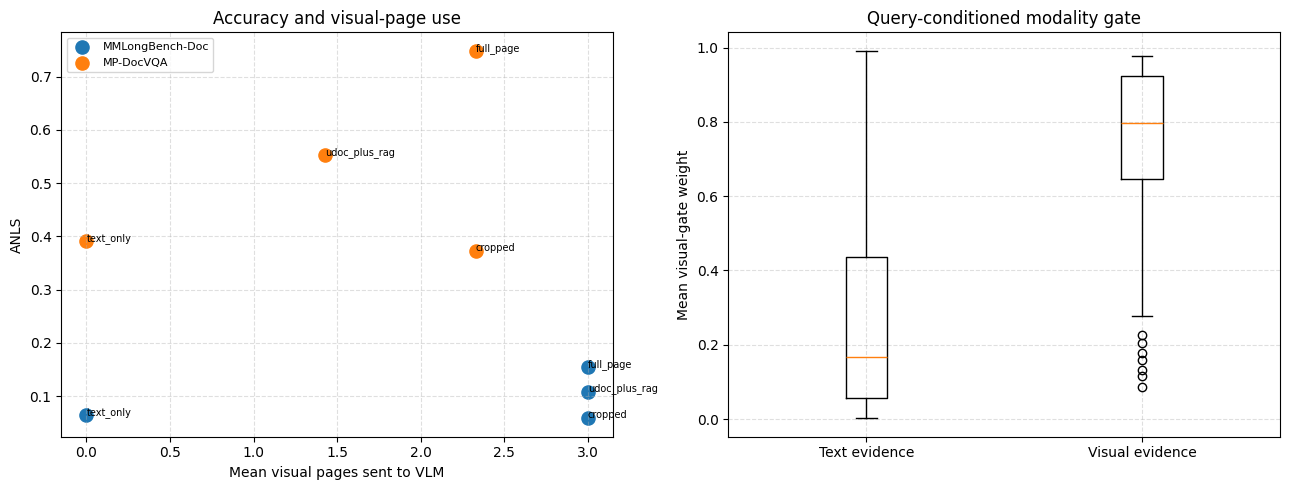

Tables, metrics, figures, and run metadata saved under /scratch/m25mac003/omnidoc_outputs


In [10]:
if "df_logs" not in globals() or df_logs.empty:
    raise RuntimeError("Track 2 predictions are missing. Run the Track 2 evaluation cell first.")
if "df_t1" not in globals():
    summary_path = Path(WORK_DIR) / "track1_ablation_summary.csv"
    df_t1 = pd.read_csv(summary_path) if summary_path.exists() else None

summary_rows = []
for source in sorted(df_logs["source"].unique()):
    for mode in MODES:
        subset = df_logs[(df_logs["source"] == source) & (df_logs["mode"] == mode)]
        if subset.empty:
            continue
        text_subset = subset[subset["needs_vision"] == 0]
        visual_subset = subset[subset["needs_vision"] == 1]
        cross_page_subset = subset[subset["is_cross_page"] == 1]
        summary_rows.append({
            "Source": source, "Mode": mode, "N": len(subset),
            "Overall_ANLS": round(subset["anls"].mean(), 4),
            "Text_ANLS": round(text_subset["anls"].mean(), 4) if len(text_subset) else None,
            "Visual_ANLS": round(visual_subset["anls"].mean(), 4) if len(visual_subset) else None,
            "CrossPage_ANLS": round(cross_page_subset["anls"].mean(), 4) if len(cross_page_subset) else None,
            "Page_Recall": round(subset["page_recall"].mean(), 4) if subset["page_recall"].notna().any() else None,
            "Avg_Visual_Pages": round(subset["vis_pages"].mean(), 2),
            "Latency_s": round(subset["latency_s"].mean(), 2),
            "NLI_Retry_Rate": round(subset["retried"].mean(), 3),
        })
df_t2 = pd.DataFrame(summary_rows)
if df_t2.empty:
    raise RuntimeError("No Track 2 result groups were available to summarize.")
df_t2.to_csv(Path(WORK_DIR) / "track2_summary.csv", index=False)
display(df_t2)
if df_t1 is not None:
    df_t1.to_latex(Path(WORK_DIR) / "table1_track1.tex", index=False, float_format="%.4f")
df_t2.to_latex(Path(WORK_DIR) / "table2_track2.tex", index=False, float_format="%.4f")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for source in df_t2["Source"].unique():
    source_rows = df_t2[df_t2["Source"] == source]
    axes[0].scatter(source_rows["Avg_Visual_Pages"], source_rows["Overall_ANLS"], s=90, label=source)
    for _, row in source_rows.iterrows():
        axes[0].annotate(row["Mode"], (row["Avg_Visual_Pages"], row["Overall_ANLS"]), fontsize=7)
axes[0].set_xlabel("Mean visual pages sent to VLM")
axes[0].set_ylabel("ANLS")
axes[0].set_title("Accuracy and visual-page use")
axes[0].grid(True, linestyle="--", alpha=0.4)
axes[0].legend(fontsize=8)

gate_frame = pd.DataFrame(gate_audit)
text_gate = gate_frame.loc[gate_frame["needs_vision"] == 0, "mean_alpha_v"] if len(gate_frame) else pd.Series(dtype=float)
visual_gate = gate_frame.loc[gate_frame["needs_vision"] == 1, "mean_alpha_v"] if len(gate_frame) else pd.Series(dtype=float)
if len(text_gate) and len(visual_gate):
    axes[1].boxplot([text_gate, visual_gate], labels=["Text evidence", "Visual evidence"])
    axes[1].set_ylabel("Mean visual-gate weight")
    axes[1].set_title("Query-conditioned modality gate")
    axes[1].grid(True, linestyle="--", alpha=0.4)
else:
    axes[1].text(0.5, 0.5, "Both query groups are required for gate comparison", ha="center", va="center")
    axes[1].set_axis_off()
fig.tight_layout()
fig.savefig(Path(WORK_DIR) / "figures" / "track2_accuracy_efficiency_gate.png", dpi=220)
plt.show()

run_record = {
    "device": str(DEVICE), "gpu_name": GPU_NAME, "vram_gib": VRAM_GB,
    "fast_check": FAST_CHECK, "seed": 42, "configuration": CFG, "vlm_id": VLM_ID,
    "software_versions": {name: version(package) for name, package in {
        "torch": "torch", "torchvision": "torchvision", "transformers": "transformers",
        "datasets": "datasets", "peft": "peft", "easyocr": "easyocr", "pymupdf": "pymupdf"}.items()},
    "track1_datasets": TRACK1_DATASETS,
    "track1_counts": TRACK1_COUNTS,
    "track2_train_document_ids": sorted({qa["doc_id"] for qa in train_qas}),
    "track2_eval_document_ids": sorted({qa["doc_id"] for qa in eval_qas}),
    "track2_document_count": len(PARSED_DOCS), "track2_qa_counts": {
        source: {"train": sum(qa["source"] == source for qa in train_qas),
                 "evaluation": sum(qa["source"] == source for qa in eval_qas)}
        for source in sorted({qa["source"] for qa in train_qas + eval_qas})},
    "output_root": WORK_DIR,
}
(Path(WORK_DIR) / "run_metadata.json").write_text(json.dumps(run_record, indent=2), encoding="utf-8")
print(f"Tables, metrics, figures, and run metadata saved under {WORK_DIR}")


In [11]:
# Thesis summary for the results currently recorded by Track 2.
# Run after the evaluation cell has created df_logs.

import numpy as np
import pandas as pd
from pathlib import Path

if "df_logs" not in globals() or df_logs.empty:
    raise RuntimeError("Track 2 results are missing. Run the evaluation cell first.")

required_columns = {
    "mode",
    "source",
    "anls",
    "page_recall",
    "vis_pages",
    "latency_s",
    "retried",
    "needs_vision",
    "is_cross_page",
}
missing_columns = required_columns - set(df_logs.columns)
if missing_columns:
    raise ValueError(f"Track 2 results are missing columns: {sorted(missing_columns)}")

BOOTSTRAP_SAMPLES = 2000
BOOTSTRAP_SEED = 42
rng = np.random.default_rng(BOOTSTRAP_SEED)


def mean_bootstrap_ci(values, samples=BOOTSTRAP_SAMPLES):
    """Percentile 95% bootstrap CI for the mean, ignoring missing values."""
    values = pd.to_numeric(pd.Series(values), errors="coerce").dropna().to_numpy()
    if len(values) == 0:
        return np.nan, np.nan, np.nan

    mean_value = float(values.mean())
    if len(values) == 1:
        return mean_value, mean_value, mean_value

    draws = rng.choice(values, size=(samples, len(values)), replace=True).mean(axis=1)
    low, high = np.quantile(draws, [0.025, 0.975])
    return mean_value, float(low), float(high)


def summarize_rows(frame, source, mode, slice_name):
    anls_mean, anls_ci_low, anls_ci_high = mean_bootstrap_ci(frame["anls"])

    page_recall = pd.to_numeric(frame["page_recall"], errors="coerce")
    latency = pd.to_numeric(frame["latency_s"], errors="coerce")
    visual_pages = pd.to_numeric(frame["vis_pages"], errors="coerce")
    retried = pd.to_numeric(frame["retried"], errors="coerce")

    return {
        "Source": source,
        "Mode": mode,
        "Slice": slice_name,
        "N": len(frame),
        "Mean_ANLS": anls_mean,
        "ANLS_95CI_Low": anls_ci_low,
        "ANLS_95CI_High": anls_ci_high,
        "Mean_Context_Evidence_Page_Recall": (
            float(page_recall.mean()) if page_recall.notna().any() else np.nan
        ),
        "Mean_Visual_Pages": (
            float(visual_pages.mean()) if visual_pages.notna().any() else np.nan
        ),
        "Mean_Latency_Seconds": (
            float(latency.mean()) if latency.notna().any() else np.nan
        ),
        "Median_Latency_Seconds": (
            float(latency.median()) if latency.notna().any() else np.nan
        ),
        "Retry_Rate": float(retried.mean()) if retried.notna().any() else np.nan,
    }


summary_rows = []

for (source, mode), group in df_logs.groupby(["source", "mode"], dropna=False):
    summary_rows.append(summarize_rows(group, source, mode, "All"))

    slice_masks = {
        "Text_Evidence": group["needs_vision"] == 0,
        "Visual_Evidence": group["needs_vision"] == 1,
        "Single_Page": group["is_cross_page"] == 0,
        "Cross_Page": group["is_cross_page"] == 1,
    }

    for slice_name, mask in slice_masks.items():
        sliced = group.loc[mask]
        if not sliced.empty:
            summary_rows.append(
                summarize_rows(sliced, source, mode, slice_name)
            )

track2_thesis_metrics = (
    pd.DataFrame(summary_rows)
    .sort_values(["Source", "Slice", "Mode"])
    .reset_index(drop=True)
)

output_dir = Path(WORK_DIR)
output_dir.mkdir(parents=True, exist_ok=True)
metrics_path = output_dir / "track2_thesis_metrics.csv"
track2_thesis_metrics.to_csv(metrics_path, index=False)

display(track2_thesis_metrics)
print(f"Saved Track 2 thesis metrics to: {metrics_path}")

# Track 1 already records weighted/macro F1 in df_t1 and per-class results
# in track1_detailed_metrics.json.
if "df_t1" in globals() and not df_t1.empty:
    track1_path = output_dir / "track1_ablation_summary.csv"
    df_t1.to_csv(track1_path, index=False)
    print(f"Saved Track 1 summary to: {track1_path}")

print(
    "Scope note: these outputs do not include ranked retrieval lists, "
    "visual-token counts, separated retrieval/generation timings, or saved "
    "pre-retry answers. Do not report R@k, MRR, NDCG, token reduction, "
    "retry accuracy gain, or entailment rate from these logs."
)

,Source,Mode,Slice,N,Mean_ANLS,ANLS_95CI_Low,ANLS_95CI_High,Mean_Context_Evidence_Page_Recall,Mean_Visual_Pages,Mean_Latency_Seconds,Median_Latency_Seconds,Retry_Rate
0,MMLongBench-Doc,cropped,All,161,0.058615,0.028489,0.093239,0.417732,3.000000,1.034581,0.955625,0.000000
1,MMLongBench-Doc,full_page,All,161,0.154463,0.105387,0.206156,0.417732,3.000000,2.054594,1.843389,0.000000
2,MMLongBench-Doc,text_only,All,161,0.064559,0.031466,0.100487,0.417732,0.000000,0.894139,0.764174,0.000000
3,MMLongBench-Doc,udoc_plus_rag,All,161,0.108870,0.066879,0.154944,0.501663,3.000000,3.589703,3.520929,0.683230
4,MMLongBench-Doc,cropped,Cross_Page,59,0.040787,0.000000,0.094431,0.319274,3.000000,1.031480,0.831256,0.000000
5,MMLongBench-Doc,full_page,Cross_Page,59,0.123709,0.051516,0.205015,0.319274,3.000000,1.966272,1.633186,0.000000
6,MMLongBench-Doc,text_only,Cross_Page,59,0.030266,0.000000,0.077482,0.319274,0.000000,0.904068,0.755430,0.000000
7,MMLongBench-Doc,udoc_plus_rag,Cross_Page,59,0.110976,0.033898,0.195317,0.428238,3.000000,3.688158,3.328505,0.694915
8,MMLongBench-Doc,cropped,Single_Page,102,0.068927,0.029289,0.119118,0.475248,3.000000,1.036375,0.968495,0.000000
9,MMLongBench-Doc,full_page,Single_Page,102,0.172251,0.110811,0.242370,0.475248,3.000000,2.105682,2.091143,0.000000


Saved Track 2 thesis metrics to: /scratch/m25mac003/omnidoc_outputs/track2_thesis_metrics.csv
Saved Track 1 summary to: /scratch/m25mac003/omnidoc_outputs/track1_ablation_summary.csv
Scope note: these outputs do not include ranked retrieval lists, visual-token counts, separated retrieval/generation timings, or saved pre-retry answers. Do not report R@k, MRR, NDCG, token reduction, retry accuracy gain, or entailment rate from these logs.


Evaluation matrices


,Source,Mode,N,Mean_ANLS,ANLS_95CI_Low,ANLS_95CI_High,Mean_Context_Evidence_Page_Recall,Mean_Visual_Pages,Mean_Latency_Seconds,Retry_Rate
0,MMLongBench-Doc,cropped,161,0.058615,0.028489,0.093239,0.417732,3.000000,1.034581,0.000000
1,MMLongBench-Doc,full_page,161,0.154463,0.105387,0.206156,0.417732,3.000000,2.054594,0.000000
2,MMLongBench-Doc,text_only,161,0.064559,0.031466,0.100487,0.417732,0.000000,0.894139,0.000000
3,MMLongBench-Doc,udoc_plus_rag,161,0.108870,0.066879,0.154944,0.501663,3.000000,3.589703,0.683230
20,MP-DocVQA,cropped,69,0.372329,0.269538,0.480677,0.869565,2.333333,0.410367,0.000000
21,MP-DocVQA,full_page,69,0.748424,0.647623,0.837564,0.869565,2.333333,1.061375,0.000000
22,MP-DocVQA,text_only,69,0.391879,0.285719,0.508277,0.869565,0.000000,0.317863,0.000000
23,MP-DocVQA,udoc_plus_rag,69,0.552005,0.444543,0.661770,0.884058,1.434783,1.188504,0.376812


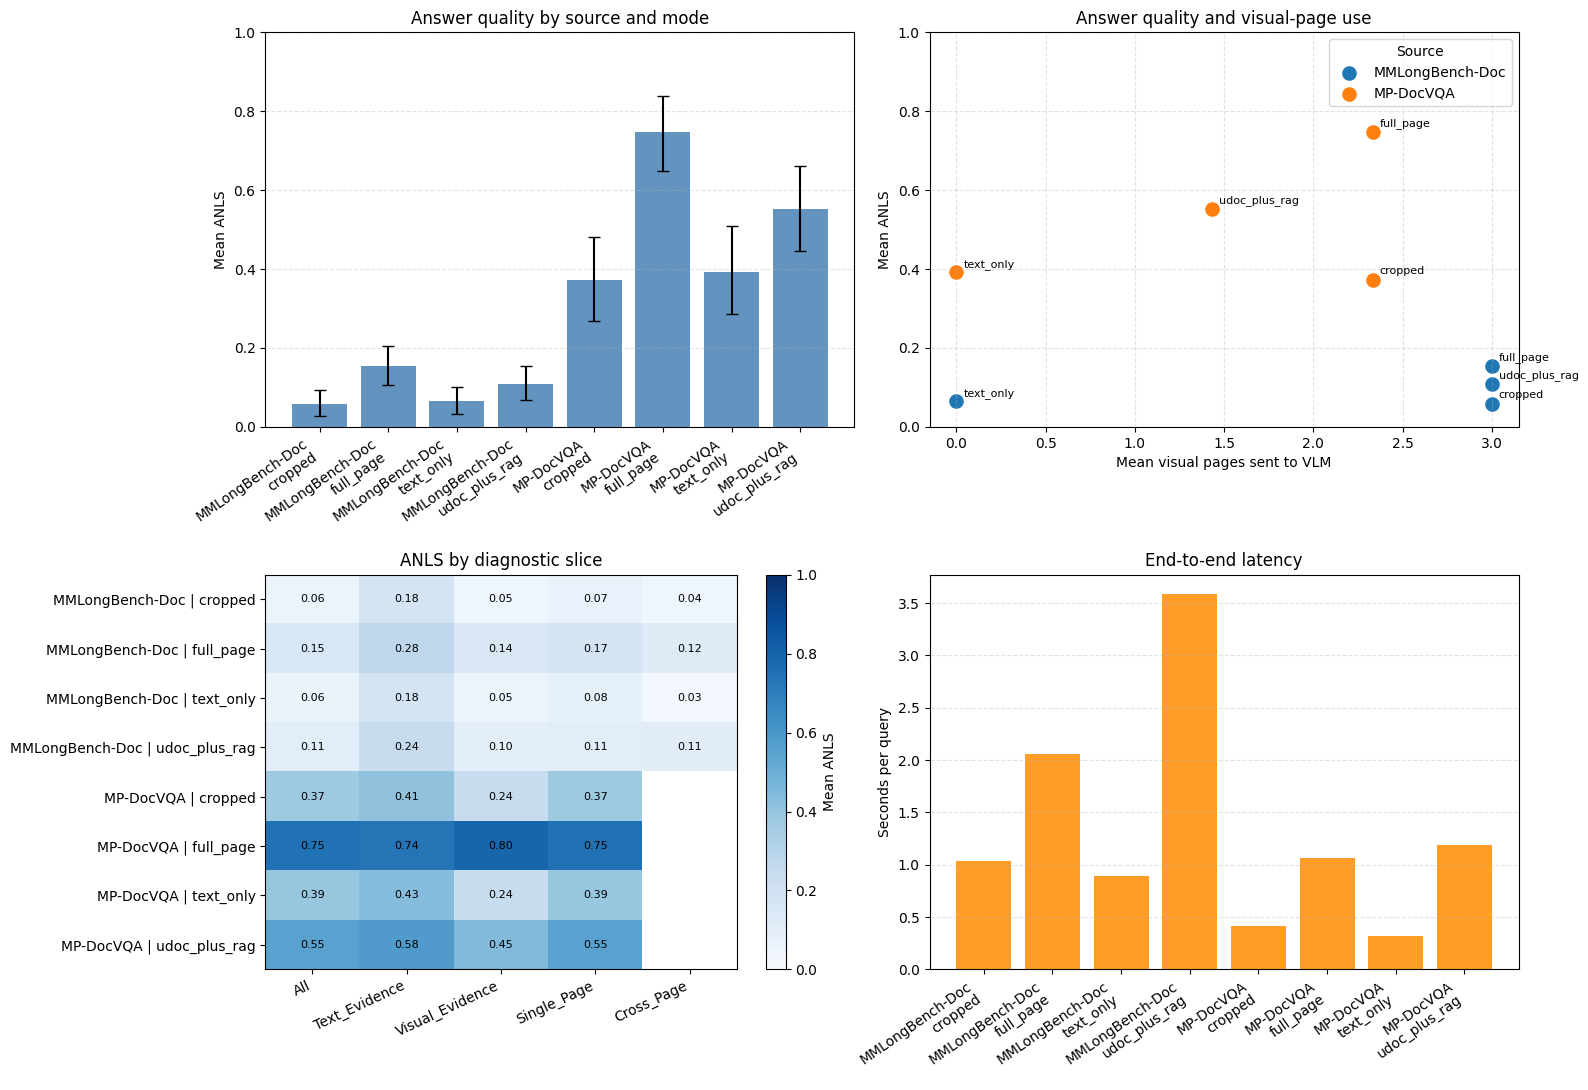

Saved Track 2 visualization: /scratch/m25mac003/omnidoc_outputs/figures/track2_thesis_results.png


,Dataset,Model,Trainable_M,Best_Validation_Weighted_F1,Weighted_F1,Macro_F1,Train_N,Validation_N,Test_N
0,funsd,0_UDoc_Baseline,17.39,0.8392,0.8326,0.7555,134,15,50
1,funsd,1_Plus_SpatialBias,17.39,0.8159,0.8257,0.7483,134,15,50
2,funsd,2_Plus_LoRA_VPool,17.98,0.8515,0.8452,0.7564,134,15,50
3,funsd,3_UDocPlus_Full,18.11,0.8341,0.8451,0.7718,134,15,50
4,cord,0_UDoc_Baseline,17.40,0.9690,0.9519,0.8130,720,80,100
5,cord,1_Plus_SpatialBias,17.40,0.9741,0.9522,0.8165,720,80,100
6,cord,2_Plus_LoRA_VPool,17.99,0.9761,0.9497,0.8156,720,80,100
7,cord,3_UDocPlus_Full,18.13,0.9704,0.9462,0.8257,720,80,100


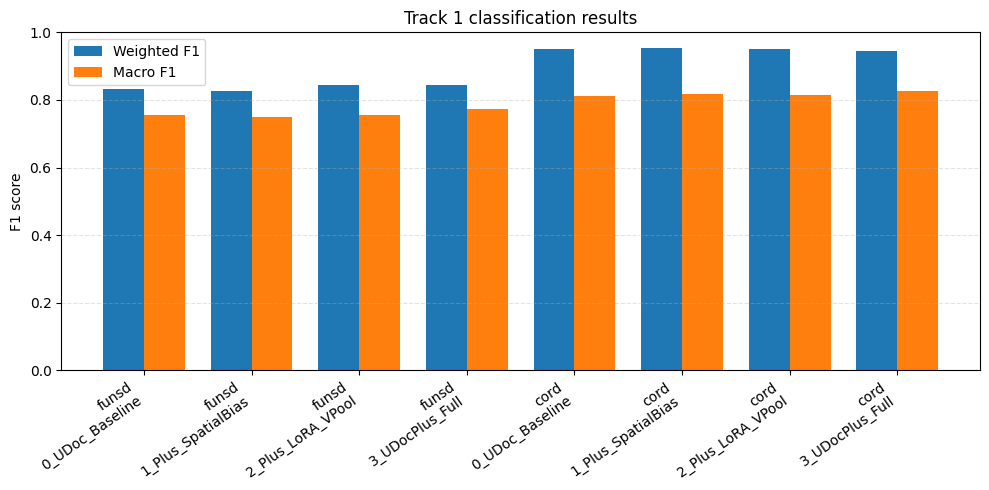

Saved Track 1 visualization: /scratch/m25mac003/omnidoc_outputs/figures/track1_f1_results.png


In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

if "track2_thesis_metrics" not in globals() or track2_thesis_metrics.empty:
    raise RuntimeError(
        "Track 2 summary is missing. Run the thesis metrics cell first."
    )

fig_dir = Path(WORK_DIR) / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)

# Show the main Track 2 results table.
overall = track2_thesis_metrics[
    track2_thesis_metrics["Slice"] == "All"
].copy()

display(
    overall[
        [
            "Source",
            "Mode",
            "N",
            "Mean_ANLS",
            "ANLS_95CI_Low",
            "ANLS_95CI_High",
            "Mean_Context_Evidence_Page_Recall",
            "Mean_Visual_Pages",
            "Mean_Latency_Seconds",
            "Retry_Rate",
        ]
    ].sort_values(["Source", "Mode"])
)

# Prepare labels used by the plots.
overall["Label"] = overall["Source"].astype(str) + "\n" + overall["Mode"].astype(str)
x = np.arange(len(overall))

mean = overall["Mean_ANLS"].to_numpy(dtype=float)
ci_low = overall["ANLS_95CI_Low"].to_numpy(dtype=float)
ci_high = overall["ANLS_95CI_High"].to_numpy(dtype=float)
lower_error = np.maximum(mean - ci_low, 0)
upper_error = np.maximum(ci_high - mean, 0)

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. ANLS with bootstrap confidence intervals.
axes[0, 0].bar(x, mean, color="steelblue", alpha=0.85)
axes[0, 0].errorbar(
    x,
    mean,
    yerr=np.vstack([lower_error, upper_error]),
    fmt="none",
    ecolor="black",
    capsize=4,
)
axes[0, 0].set_xticks(x)
axes[0, 0].set_xticklabels(overall["Label"], rotation=35, ha="right")
axes[0, 0].set_ylim(0, 1)
axes[0, 0].set_ylabel("Mean ANLS")
axes[0, 0].set_title("Answer quality by source and mode")
axes[0, 0].grid(axis="y", linestyle="--", alpha=0.35)

# 2. Accuracy versus visual pages sent.
for source, group in overall.groupby("Source"):
    axes[0, 1].scatter(
        group["Mean_Visual_Pages"],
        group["Mean_ANLS"],
        s=90,
        label=str(source),
    )
    for _, row in group.iterrows():
        axes[0, 1].annotate(
            str(row["Mode"]),
            (row["Mean_Visual_Pages"], row["Mean_ANLS"]),
            xytext=(5, 4),
            textcoords="offset points",
            fontsize=8,
        )
axes[0, 1].set_xlabel("Mean visual pages sent to VLM")
axes[0, 1].set_ylabel("Mean ANLS")
axes[0, 1].set_ylim(0, 1)
axes[0, 1].set_title("Answer quality and visual-page use")
axes[0, 1].grid(True, linestyle="--", alpha=0.35)
axes[0, 1].legend(title="Source")

# 3. ANLS across the available diagnostic slices.
slice_order = [
    "All",
    "Text_Evidence",
    "Visual_Evidence",
    "Single_Page",
    "Cross_Page",
]
slice_data = track2_thesis_metrics[
    track2_thesis_metrics["Slice"].isin(slice_order)
].copy()
slice_data["Row"] = slice_data["Source"].astype(str) + " | " + slice_data["Mode"]
slice_table = slice_data.pivot_table(
    index="Row",
    columns="Slice",
    values="Mean_ANLS",
    aggfunc="first",
).reindex(columns=slice_order)

if not slice_table.empty:
    values = slice_table.to_numpy(dtype=float)
    image = axes[1, 0].imshow(values, aspect="auto", vmin=0, vmax=1, cmap="Blues")
    axes[1, 0].set_yticks(np.arange(len(slice_table.index)))
    axes[1, 0].set_yticklabels(slice_table.index)
    axes[1, 0].set_xticks(np.arange(len(slice_table.columns)))
    axes[1, 0].set_xticklabels(slice_table.columns, rotation=25, ha="right")
    axes[1, 0].set_title("ANLS by diagnostic slice")
    for row_idx in range(values.shape[0]):
        for col_idx in range(values.shape[1]):
            if np.isfinite(values[row_idx, col_idx]):
                axes[1, 0].text(
                    col_idx,
                    row_idx,
                    f"{values[row_idx, col_idx]:.2f}",
                    ha="center",
                    va="center",
                    fontsize=8,
                )
    fig.colorbar(image, ax=axes[1, 0], label="Mean ANLS")
else:
    axes[1, 0].set_axis_off()
    axes[1, 0].text(0.5, 0.5, "No slice results available", ha="center")

# 4. Mean end-to-end latency by source and mode.
latency = overall["Mean_Latency_Seconds"].to_numpy(dtype=float)
axes[1, 1].bar(x, latency, color="darkorange", alpha=0.85)
axes[1, 1].set_xticks(x)
axes[1, 1].set_xticklabels(overall["Label"], rotation=35, ha="right")
axes[1, 1].set_ylabel("Seconds per query")
axes[1, 1].set_title("End-to-end latency")
axes[1, 1].grid(axis="y", linestyle="--", alpha=0.35)

fig.tight_layout()
track2_plot_path = fig_dir / "track2_thesis_results.png"
fig.savefig(track2_plot_path, dpi=220, bbox_inches="tight")
plt.show()
print(f"Saved Track 2 visualization: {track2_plot_path}")

# Show Track 1 results and plot F1 scores if the table is available.
track1 = globals().get("df_t1")
if track1 is None:
    track1_path = Path(WORK_DIR) / "track1_ablation_summary.csv"
    if track1_path.exists():
        track1 = pd.read_csv(track1_path)

if track1 is not None and not track1.empty:
    display(track1)

    needed = {"Dataset", "Model", "Weighted_F1", "Macro_F1"}
    if needed.issubset(track1.columns):
        track1_plot = track1.copy()
        track1_plot["Label"] = (
            track1_plot["Dataset"].astype(str)
            + "\n"
            + track1_plot["Model"].astype(str)
        )
        xx = np.arange(len(track1_plot))
        width = 0.38

        fig1, ax1 = plt.subplots(figsize=(max(10, len(xx) * 0.8), 5))
        ax1.bar(
            xx - width / 2,
            track1_plot["Weighted_F1"],
            width,
            label="Weighted F1",
        )
        ax1.bar(
            xx + width / 2,
            track1_plot["Macro_F1"],
            width,
            label="Macro F1",
        )
        ax1.set_xticks(xx)
        ax1.set_xticklabels(track1_plot["Label"], rotation=35, ha="right")
        ax1.set_ylim(0, 1)
        ax1.set_ylabel("F1 score")
        ax1.set_title("Track 1 classification results")
        ax1.grid(axis="y", linestyle="--", alpha=0.35)
        ax1.legend()
        fig1.tight_layout()

        track1_plot_path = fig_dir / "track1_f1_results.png"
        fig1.savefig(track1_plot_path, dpi=220, bbox_inches="tight")
        plt.show()
        print(f"Saved Track 1 visualization: {track1_plot_path}")
else:
    print("Track 1 summary table was not found; skipping its plot.")

Model working showcase

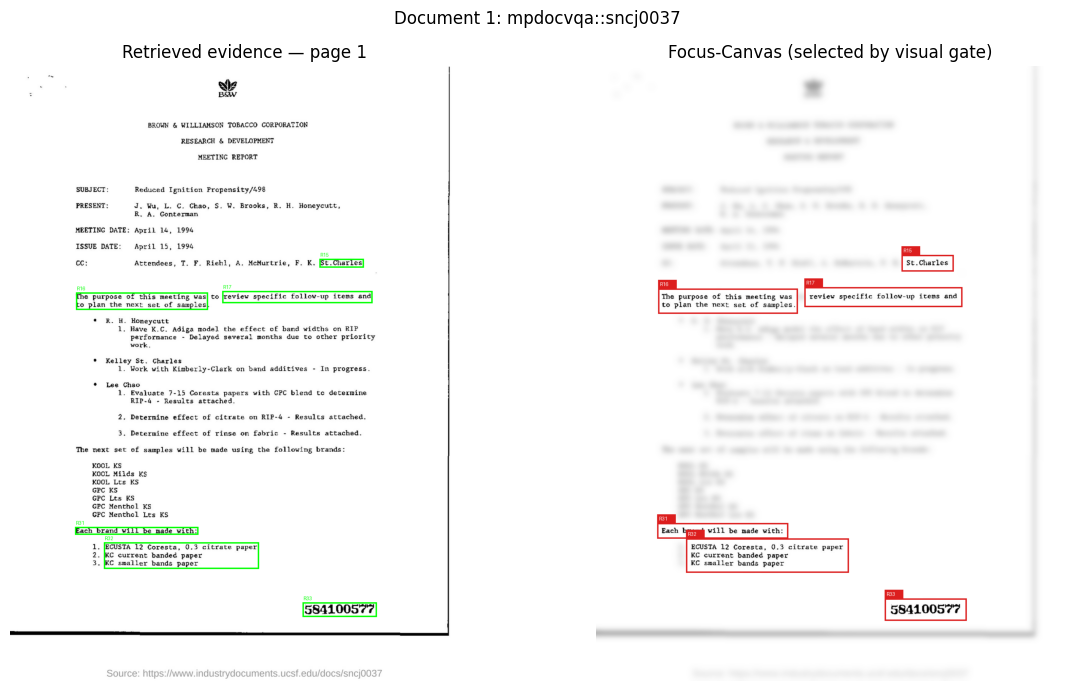


TEST DOCUMENT 1: mpdocvqa::sncj0037
Pages: 4 | Extracted regions: 87
Question: what is the porosity for paper code 99103A?
Reference answer(s): ['12']
Pages selected for visual input: [1, 4, 3]
Showcase image saved to: /scratch/m25mac003/omnidoc_outputs/figures/five_document_showcase/showcase_1.png

Top hybrid retrieval candidates and modality-gate scores:


,Region,Page,Type,Fusion score,Visual gate,Text gate,Text
0,R32,1,text,0.0323,0.000,1.000,"ECUSTA 12 Coresta, 0.3 citrate paper KC curren..."
1,R74,4,table,0.0167,0.077,0.923,"8 5 $ Fsff ffsttft & E 1 3567F Fs-*79""p7nXE 0 ..."
2,R16,1,text,0.0164,0.041,0.959,The Purpose this mee= ting Kas to Plan the nex...
3,R70,3,table,0.0164,0.325,0.675,PLf477.Wp
4,R28,1,text,0.0161,0.032,0.968,The next set of samples will
5,R85,4,table,0.0161,0.984,0.016,W 0 E 888 5%
6,R18,1,text,0.0159,0.037,0.963,Koneycutt Have K.C_ Adiga model the effect of ...
7,R62,3,text,0.0159,0.172,0.828,LI/1MI/ISE 2NI /4SE


Saved evaluation predictions for this question:


,mode,pred,anls,vis_pages,latency_s
212,text_only,Insufficient evidence,0.0,0,0.226824
442,full_page,12,1.0,3,1.097127
672,cropped,Insufficient evidence,0.0,3,0.319019
902,udoc_plus_rag,Insufficient evidence,0.0,3,2.460723


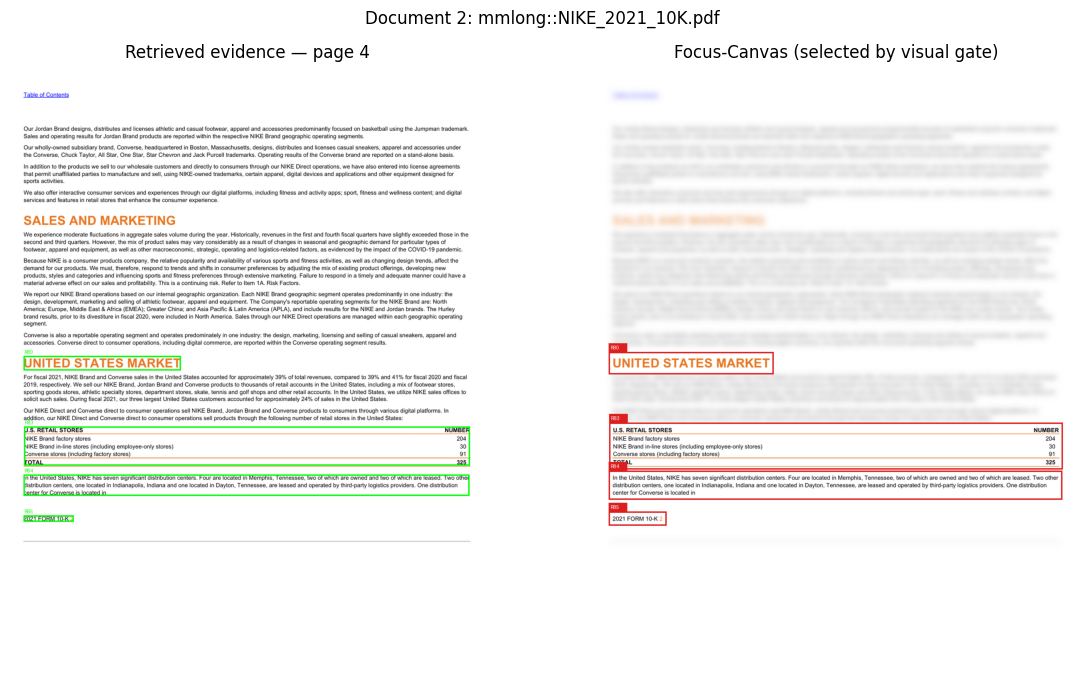


TEST DOCUMENT 2: mmlong::NIKE_2021_10K.pdf
Pages: 60 | Extracted regions: 864
Question: What is payables  turnover in FY2021 for Nike? Round your answer to two decimal places.
Reference answer(s): ['9.67']
Pages selected for visual input: [4, 59, 18]
Showcase image saved to: /scratch/m25mac003/omnidoc_outputs/figures/five_document_showcase/showcase_2.png

Top hybrid retrieval candidates and modality-gate scores:


,Region,Page,Type,Fusion score,Visual gate,Text gate,Text
0,R84,4,text,0.0167,0.121,0.879,"In the United States, NIKE has seven significa..."
1,R852,59,text,0.0167,0.054,0.946,"YEAR ENDED MAY 31, (In millions, except per sh..."
2,R267,18,text,0.0164,0.015,0.985,Risks specific to our digital commerce busines...
3,R362,26,text,0.0164,0.960,0.040,"In the United States, NIKE has seven significa..."
4,R162,9,text,0.0161,0.002,0.998,• We offer two weeks of paid COVID-19 sick lea...
5,R441,33,text,0.0161,1.000,0.000,"(Dollars in millions, except per share data) F..."
6,R103,6,text,0.0159,0.665,0.335,We are supplied by 344 apparel factories locat...
7,R710,47,text,0.0159,0.006,0.994,"On July 23, 2019, we filed a shelf registratio..."


Saved evaluation predictions for this question:


,mode,pred,anls,vis_pages,latency_s
81,text_only,Insufficient evidence,0.0,0,1.218395
311,full_page,Insufficient evidence,0.0,3,2.182780
541,cropped,Insufficient evidence,0.0,3,1.317847
771,udoc_plus_rag,Insufficient evidence,0.0,3,5.205557


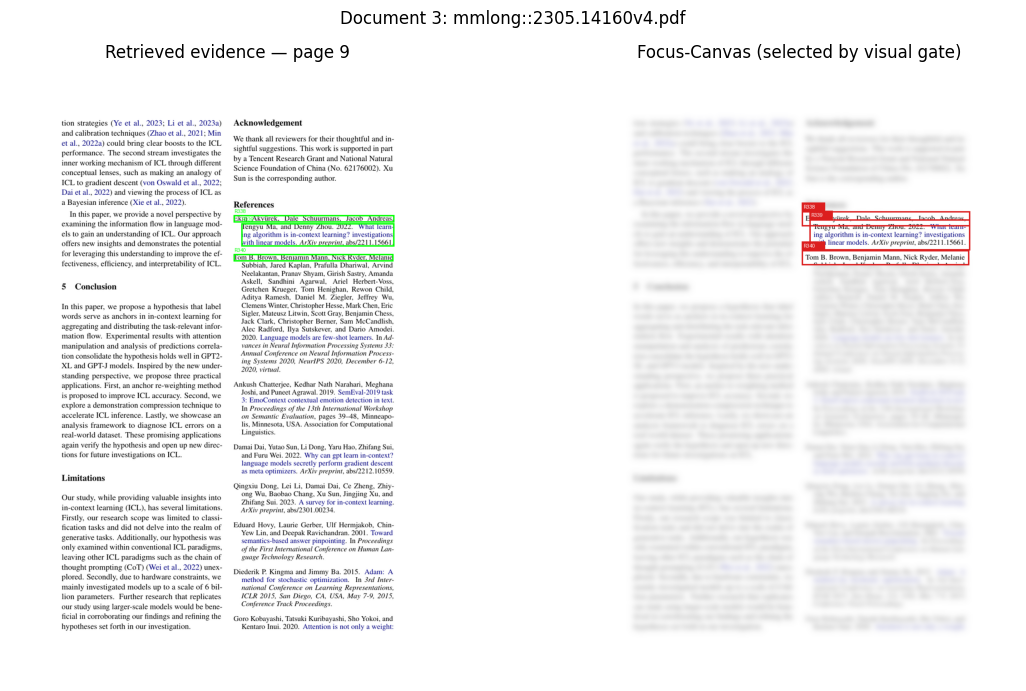


TEST DOCUMENT 3: mmlong::2305.14160v4.pdf
Pages: 16 | Extracted regions: 690
Question: What is the most confusing category of Abbreviation?
Reference answer(s): ['Description']
Pages selected for visual input: [9, 8, 1]
Showcase image saved to: /scratch/m25mac003/omnidoc_outputs/figures/five_document_showcase/showcase_3.png

Top hybrid retrieval candidates and modality-gate scores:


,Region,Page,Type,Fusion score,Visual gate,Text gate,Text
0,R339,9,text,0.0310,1.000,0.000,"Tengyu Ma, and Denny Zhou. 2022. What learn- i..."
1,R303,8,text,0.0167,0.992,0.008,"Lastly, we perform an error analysis for ICL b..."
2,R323,8,caption,0.0167,1.000,0.000,Figure 6: Predicted and real confusion matrix ...
3,R3,1,text,0.0164,1.000,0.000,† National Key Laboratory for Multimedia Infor...
4,R307,8,text,0.0164,0.993,0.007,ˆ k (see Appendix J for details). We anticipat...
5,R284,7,text,0.0161,0.601,0.399,The Text anchor method is included to demon- s...
6,R359,10,text,0.0161,1.000,0.000,Qiu. 2023a. Unified demonstration retriever fo...
7,R333,9,text,0.0159,1.000,0.000,"Our study, while providing valuable insights i..."


Saved evaluation predictions for this question:


,mode,pred,anls,vis_pages,latency_s
48,text_only,Insufficient evidence,0.0,0,0.764174
278,full_page,The most confusing category for Abbreviation i...,0.0,3,4.219967
508,cropped,Insufficient evidence,0.0,3,0.815101
738,udoc_plus_rag,The most confusing category is Description-Ent...,0.0,3,1.896359


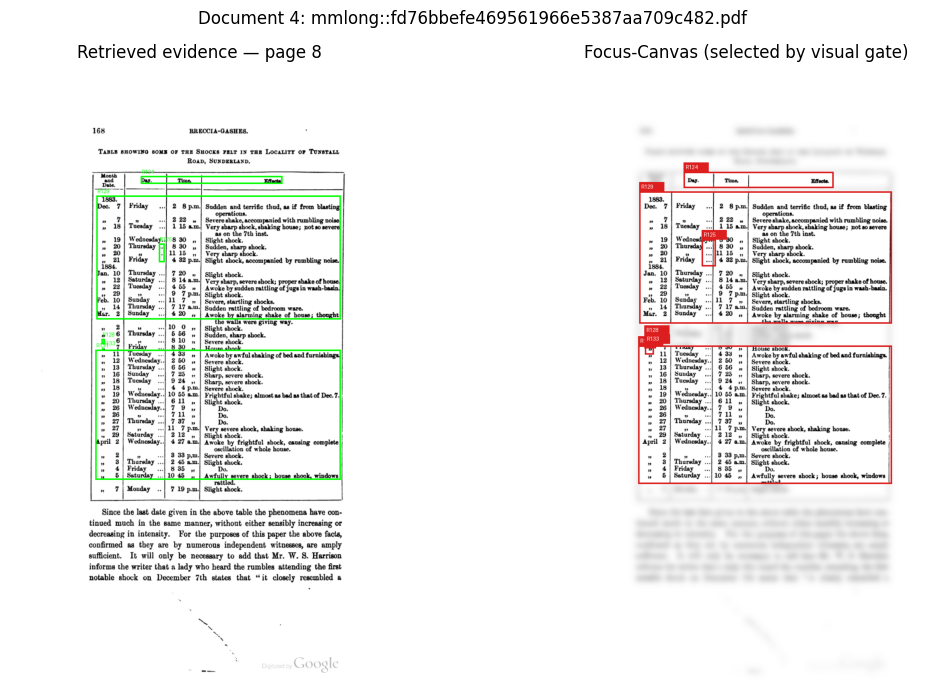


TEST DOCUMENT 4: mmlong::fd76bbefe469561966e5387aa709c482.pdf
Pages: 17 | Extracted regions: 406
Question: What degree does LEBOUR have?
Reference answer(s): ['M.A.']
Pages selected for visual input: [8, 9, 12]
Showcase image saved to: /scratch/m25mac003/omnidoc_outputs/figures/five_document_showcase/showcase_4.png

Top hybrid retrieval candidates and modality-gate scores:


,Region,Page,Type,Fusion score,Visual gate,Text gate,Text
0,R129,8,text,0.0167,0.005,0.995,1883 . Dec. 7 Friday 2 8 p.m. Sudden and terri...
1,R158,9,text,0.0167,0.996,0.004,scarcely does justice to its singular mode of ...
2,R131,8,text,0.0164,1.000,0.000,11 Tuesday 4 33 Awoke by awful shaking of bed ...
3,R234,12,text,0.0164,0.410,0.590,nevertheless in some slight degree also owe th...
4,R18,1,text,0.0161,0.993,0.007,and others . * It is not intended in the prese...
5,R74,4,figure,0.0161,0.941,0.059,[Visual Figure on Page 4]
6,R292,14,figure,0.0159,0.892,0.108,[Visual Figure on Page 14]
7,R385,17,text,0.0159,0.921,0.079,this did not in the slightest degree militate ...


Saved evaluation predictions for this question:


,mode,pred,anls,vis_pages,latency_s
53,text_only,Insufficient evidence,0.0,0,0.595947
283,full_page,Insufficient evidence,0.0,3,1.248779
513,cropped,Insufficient evidence,0.0,3,0.670454
743,udoc_plus_rag,Insufficient evidence,0.0,3,2.798528


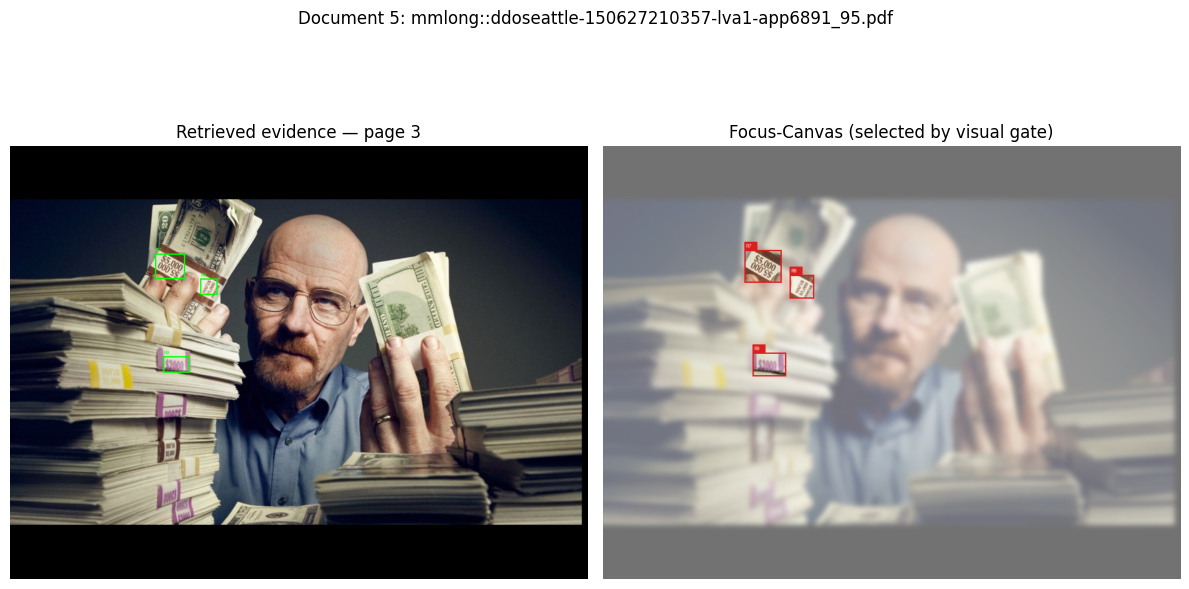


TEST DOCUMENT 5: mmlong::ddoseattle-150627210357-lva1-app6891_95.pdf
Pages: 60 | Extracted regions: 288
Question: According to the slides, what are the things that a data-driven person has?
Reference answer(s): ["['a goals first approach', 'an objective, inquisitive culture', 'a visible, clear articulated strategy', 'strong data leadership', 'a strong testing culture', 'an open, sharing culture', 'a self-service culture', 'a broad data literacy']"]
Pages selected for visual input: [3, 59, 10]
Showcase image saved to: /scratch/m25mac003/omnidoc_outputs/figures/five_document_showcase/showcase_5.png

Top hybrid retrieval candidates and modality-gate scores:


,Region,Page,Type,Fusion score,Visual gate,Text gate,Text
0,R8,3,table,0.0167,0.999,0.001,3
1,R279,59,text,0.0167,0.999,0.001,Creating a Data-Driven Organization Practical ...
2,R24,10,table,0.0164,0.999,0.001,"1 5, 0 E 4.0 4 3,0 9 2,0 1,0 1 0,0 Wed 18: 0..."
3,R76,22,text,0.0164,0.803,0.197,"you get surprises more often, and surprises ar..."
4,R34,12,text,0.0161,0.935,0.065,OPTIMISATION Whal s the best that can happen? ...
5,R217,48,text,0.0161,0.996,0.004,15% 20% 25% Share of Respondents
6,R9,3,text,0.0159,0.998,0.002,KAA
7,R203,46,text,0.0159,1.000,0.000,Communication of the benefits of data-driven d...


Saved evaluation predictions for this question:


,mode,pred,anls,vis_pages,latency_s
146,text_only,Insufficient evidence,0.0,0,0.667004
376,full_page,Insufficient evidence,0.0,3,1.541240
606,cropped,Insufficient evidence,0.0,3,0.771614
836,udoc_plus_rag,Insufficient evidence,0.0,3,3.273175



Five-document showcase completed.


,Document,Question,Reference answer(s),Gate-selected pages,Image
0,mpdocvqa::sncj0037,what is the porosity for paper code 99103A?,[12],"[1, 4, 3]",/scratch/m25mac003/omnidoc_outputs/figures/fiv...
1,mmlong::NIKE_2021_10K.pdf,What is payables turnover in FY2021 for Nike?...,[9.67],"[4, 59, 18]",/scratch/m25mac003/omnidoc_outputs/figures/fiv...
2,mmlong::2305.14160v4.pdf,What is the most confusing category of Abbrevi...,[Description],"[9, 8, 1]",/scratch/m25mac003/omnidoc_outputs/figures/fiv...
3,mmlong::fd76bbefe469561966e5387aa709c482.pdf,What degree does LEBOUR have?,[M.A.],"[8, 9, 12]",/scratch/m25mac003/omnidoc_outputs/figures/fiv...
4,mmlong::ddoseattle-150627210357-lva1-app6891_9...,"According to the slides, what are the things t...","[['a goals first approach', 'an objective, inq...","[3, 59, 10]",/scratch/m25mac003/omnidoc_outputs/figures/fiv...


In [13]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

if "TEST_INDEX" not in globals() or not TEST_INDEX:
    raise RuntimeError("TEST_INDEX is missing. Run the Track 2 indexing cell first.")
if "eval_qas" not in globals() or not eval_qas:
    raise RuntimeError("No test questions found in eval_qas. Run the data preparation cells first.")

qa_by_doc = {}
for qa in eval_qas:
    if qa["doc_id"] in TEST_INDEX:
        qa_by_doc.setdefault(qa["doc_id"], []).append(qa)

doc_ids = sorted(qa_by_doc)
if len(doc_ids) < 5:
    raise ValueError(
        f"Need at least 5 test documents for the showcase; found {len(doc_ids)}."
    )

showcase_rng = random.Random(42)
sampled_doc_ids = showcase_rng.sample(doc_ids, 5)
showcase_dir = Path(WORK_DIR) / "figures" / "five_document_showcase"
showcase_dir.mkdir(parents=True, exist_ok=True)

# Use existing evaluation results when available, so this cell does not
# rerun Qwen generation.
saved_logs = globals().get("df_logs")
if saved_logs is None and "all_logs" in globals():
    saved_logs = pd.DataFrame(all_logs)


def get_saved_answers(doc_id, query):
    if saved_logs is None or saved_logs.empty:
        return pd.DataFrame()

    matches = saved_logs[
        (saved_logs["doc_id"] == doc_id)
        & (saved_logs["query"] == query)
    ]
    columns = [col for col in ("mode", "pred", "anls", "vis_pages", "latency_s") if col in matches.columns]
    return matches[columns].drop_duplicates("mode")


def draw_region_boxes(image, regions, color="lime"):
    """Draw retrieved regions and their IDs on a copy of the page."""
    from PIL import ImageDraw

    marked = image.convert("RGB").copy()
    draw = ImageDraw.Draw(marked)
    width, height = marked.size

    for region in regions:
        x1, y1, x2, y2, _, _ = region["box_6d"]
        box = (
            int(x1 * width),
            int(y1 * height),
            int(x2 * width),
            int(y2 * height),
        )
        draw.rectangle(box, outline=color, width=3)
        draw.text((box[0] + 2, max(0, box[1] - 14)), f'R{region["id"]}', fill=color)

    return marked


showcase_rows = []

for sample_number, doc_id in enumerate(sampled_doc_ids, start=1):
    qa = showcase_rng.choice(qa_by_doc[doc_id])
    indexed_doc = TEST_INDEX[doc_id]
    query = qa["query"]

    # Run the actual hybrid retrieval plus one-hop graph expansion and gate.
    retrieved_regions, alpha_v, alpha_s, fused = retrieve_and_gate(
        indexed_doc,
        query,
        top_k=5,
        hops=1,
    )

    # The highest fusion scores are the initial retrieval candidates.
    top_region_ids = sorted(
        fused,
        key=lambda region_id: (-fused[region_id], region_id),
    )[:8]
    regions_by_id = {region["id"]: region for region in indexed_doc["regions"]}
    top_regions = [
        regions_by_id[region_id]
        for region_id in top_region_ids
        if region_id in regions_by_id
    ]

    region_rows = []
    for region in top_regions:
        region_id = region["id"]
        region_rows.append(
            {
                "Region": f'R{region_id}',
                "Page": int(region["page"]) + 1,
                "Type": region["type"],
                "Fusion score": round(float(fused.get(region_id, 0.0)), 4),
                "Visual gate": round(float(alpha_v[region_id]), 3),
                "Text gate": round(float(alpha_s[region_id]), 3),
                "Text": str(region["text"])[:180],
            }
        )

    # Match vlm_generate's page ranking and visual-gate decision.
    selected_regions = sorted(
        retrieved_regions,
        key=lambda region: (-fused.get(region["id"], 0.0), region["id"]),
    )[:48]

    regions_by_page = {}
    for region in selected_regions:
        regions_by_page.setdefault(region["page"], []).append(region)

    ranked_pages = sorted(
        regions_by_page,
        key=lambda page: max(
            fused.get(region["id"], 0.0)
            for region in regions_by_page[page]
        ),
        reverse=True,
    )

    visual_candidates = [
        page
        for page in ranked_pages
        if any(
            alpha_v[region["id"]] >= alpha_s[region["id"]]
            or region["type"] in ("table", "figure")
            for region in regions_by_page[page]
        )
    ]
    visual_pages = visual_candidates[:3]

    # Show the strongest gate-selected page. If the gate chose no image,
    # show the highest-ranked page as a diagnostic and label it accordingly.
    if visual_pages:
        showcase_page = visual_pages[0]
        page_title_suffix = "selected by visual gate"
    elif ranked_pages:
        showcase_page = ranked_pages[0]
        page_title_suffix = "top page; gate sent no image"
    else:
        showcase_page = 0
        page_title_suffix = "no retrieved page"

    page_regions = regions_by_page.get(showcase_page, [])
    raw_page = indexed_doc["pages"][showcase_page]
    boxed_page = draw_region_boxes(raw_page, page_regions)
    focus_canvas = render_focus_canvas(raw_page, page_regions)

    # Save a side-by-side image for use in thesis slides or notes.
    fig, axes = plt.subplots(1, 2, figsize=(12, 7))
    axes[0].imshow(boxed_page)
    axes[0].set_title(f"Retrieved evidence — page {showcase_page + 1}")
    axes[0].axis("off")
    axes[1].imshow(focus_canvas)
    axes[1].set_title(f"Focus-Canvas ({page_title_suffix})")
    axes[1].axis("off")
    fig.suptitle(f"Document {sample_number}: {doc_id}", fontsize=12)
    fig.tight_layout()

    image_path = showcase_dir / f"showcase_{sample_number}.png"
    fig.savefig(image_path, dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"\n{'=' * 80}")
    print(f"TEST DOCUMENT {sample_number}: {doc_id}")
    print(f"Pages: {len(indexed_doc['pages'])} | Extracted regions: {len(indexed_doc['regions'])}")
    print(f"Question: {query}")
    print(f"Reference answer(s): {qa.get('answers', [])}")
    print(
        "Pages selected for visual input:",
        [page + 1 for page in visual_pages] if visual_pages else "None",
    )
    print(f"Showcase image saved to: {image_path}")

    if region_rows:
        print("\nTop hybrid retrieval candidates and modality-gate scores:")
        display(pd.DataFrame(region_rows))

    answer_rows = get_saved_answers(doc_id, query)
    if not answer_rows.empty:
        print("Saved evaluation predictions for this question:")
        display(answer_rows)
    else:
        print(
            "No saved prediction row matched this question. "
            "Run the evaluation cell to populate df_logs."
        )

    showcase_rows.append(
        {
            "Document": doc_id,
            "Question": query,
            "Reference answer(s)": qa.get("answers", []),
            "Gate-selected pages": [page + 1 for page in visual_pages],
            "Image": str(image_path),
        }
    )

print("\nFive-document showcase completed.")
display(pd.DataFrame(showcase_rows))

Random document test


In [ ]:
from pathlib import Path
import uuid
import numpy as np
import pandas as pd
import torch
import faiss
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

upload_widget = widgets.FileUpload(
    accept=".pdf,application/pdf",
    multiple=False,
    description="Upload PDF",
)
question_widget = widgets.Textarea(
    placeholder="Type a question about the uploaded document",
    description="Question:",
    layout=widgets.Layout(width="700px", height="80px"),
)
run_button = widgets.Button(
    description="Run question",
    button_style="primary",
    icon="play",
)
output_widget = widgets.Output()


def get_uploaded_pdf(upload_value):
    """Support both ipywidgets 7 and 8 FileUpload value formats."""
    if not upload_value:
        raise ValueError("Upload a PDF first.")

    if isinstance(upload_value, dict):  # ipywidgets 7
        filename, file_info = next(iter(upload_value.items()))
        content = file_info["content"]
    else:  # ipywidgets 8
        file_info = upload_value[0]
        filename = file_info.get("name", "uploaded_document.pdf")
        content = file_info["content"]

    return Path(filename).name, bytes(content)


def run_uploaded_document(_button):
    with output_widget:
        output_widget.clear_output()

        try:
            if "udoc_rag" not in globals() or "VLM" not in globals():
                raise RuntimeError(
                    "Load the retriever and VLM first by running the notebook's "
                    "Track 2 model-loading cells."
                )

            question = question_widget.value.strip()
            if not question:
                raise ValueError("Enter a question about the PDF.")

            filename, pdf_bytes = get_uploaded_pdf(upload_widget.value)
            if not filename.lower().endswith(".pdf"):
                raise ValueError("Please upload a PDF file.")

            upload_dir = Path(WORK_DIR) / "pdfs" / "interactive_uploads"
            upload_dir.mkdir(parents=True, exist_ok=True)
            pdf_path = upload_dir / f"{uuid.uuid4().hex}_{filename}"
            pdf_path.write_bytes(pdf_bytes)

            print(f"Processing uploaded document: {filename}")

            # Parse pages and regions, then create the cross-page graph.
            pages, regions = parse_pdf(pdf_path)
            graph, adjacency = build_cross_page_graph(regions)
            new_doc = {
                "pages": pages,
                "regions": regions,
                "graph": graph,
                "bridge_adj": adjacency,
            }

            # Encode the document and create dense and lexical indexes.
            udoc_rag.eval()
            imgs, boxes_px, boxes_6d, ids, mask, page_ids, adj, region_ids = (
                pack_doc_tensors(new_doc)
            )

            with torch.no_grad():
                encoded = udoc_rag.encode_long_doc(
                    imgs,
                    boxes_px,
                    boxes_6d,
                    ids,
                    mask,
                    page_ids,
                    adj,
                )
                embeddings = (
                    encoded["rag_embs"]
                    .float()
                    .cpu()
                    .numpy()
                    .astype("float32")
                )

            dense_index = faiss.IndexFlatIP(embeddings.shape[1])
            dense_index.add(embeddings)
            bm25_index = BM25Okapi(
                [region["text"].lower().split() or ["empty"] for region in regions]
            )

            indexed_doc = {
                **new_doc,
                "faiss": dense_index,
                "bm25": bm25_index,
                "tensors": (
                    imgs.cpu(),
                    boxes_px.cpu(),
                    boxes_6d.cpu(),
                    ids.cpu(),
                    mask.cpu(),
                    page_ids.cpu(),
                    adj.cpu(),
                ),
            }

            # Hybrid retrieval plus one-hop cross-page graph expansion.
            retrieved, alpha_v, alpha_s, fused = retrieve_and_gate(
                indexed_doc,
                question,
                top_k=5,
                hops=1,
            )

            # Generate the answer using retrieved evidence and the modality gate.
            answer, visual_page_count, context_pages = vlm_generate(
                indexed_doc,
                question,
                retrieved,
                alpha_v,
                alpha_s,
                fused,
                mode="udoc_plus_rag",
            )

            print(f"\nQuestion: {question}")
            print(f"\nAnswer: {answer}")
            print(f"Pages parsed: {len(pages)}")
            print(f"Regions extracted: {len(regions)}")
            print(f"Evidence pages in context: {[p + 1 for p in context_pages]}")
            print(f"Visual pages sent to the VLM: {visual_page_count}")

            # Show the highest-scoring retrieval candidates and gate outputs.
            region_by_id = {region["id"]: region for region in regions}
            top_ids = sorted(
                fused,
                key=lambda region_id: (-fused[region_id], region_id),
            )[:10]

            evidence_rows = []
            for region_id in top_ids:
                region = region_by_id.get(region_id)
                if region is None:
                    continue

                evidence_rows.append(
                    {
                        "Region": f"R{region_id}",
                        "Page": int(region["page"]) + 1,
                        "Type": region["type"],
                        "Fusion score": round(float(fused[region_id]), 4),
                        "Visual gate": round(float(alpha_v[region_id]), 3),
                        "Text gate": round(float(alpha_s[region_id]), 3),
                        "Text": str(region["text"])[:200],
                    }
                )

            print("\nTop retrieved evidence:")
            display(pd.DataFrame(evidence_rows))

            # Show a Focus-Canvas for the highest-ranked page selected by the gate.
            selected = sorted(
                retrieved,
                key=lambda region: (
                    -fused.get(region["id"], 0.0),
                    region["id"],
                ),
            )[:48]

            regions_by_page = {}
            for region in selected:
                regions_by_page.setdefault(region["page"], []).append(region)

            ranked_pages = sorted(
                regions_by_page,
                key=lambda page: max(
                    fused.get(region["id"], 0.0)
                    for region in regions_by_page[page]
                ),
                reverse=True,
            )

            visual_candidates = [
                page
                for page in ranked_pages
                if any(
                    alpha_v[region["id"]] >= alpha_s[region["id"]]
                    or region["type"] in ("table", "figure")
                    for region in regions_by_page[page]
                )
            ]
            visual_pages = visual_candidates[:3]

            if visual_pages:
                page_id = visual_pages[0]
                canvas = render_focus_canvas(
                    pages[page_id],
                    regions_by_page[page_id],
                )
                plt.figure(figsize=(9, 10))
                plt.imshow(canvas)
                plt.title(f"Focus-Canvas sent to the VLM — page {page_id + 1}")
                plt.axis("off")
                plt.show()
            else:
                print("\nThe visual gate selected no page image for this question.")

        except Exception as exc:
            print(f"{type(exc).__name__}: {exc}")


run_button.on_click(run_uploaded_document)

display(
    widgets.VBox(
        [
            widgets.HTML("<b>Ask a question about a PDF</b>"),
            upload_widget,
            question_widget,
            run_button,
            output_widget,
        ]
    )
)

In [15]:
print("udoc_rag loaded:", "udoc_rag" in globals())
print("VLM loaded:", "VLM" in globals())

udoc_rag loaded: True
VLM loaded: True
